<a href="https://colab.research.google.com/github/saulobortolon/Quaternios-Kalman-CC/blob/main/kalman/notebooks/pepe_kalman_parte1_ekf_iekf.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Abrir no Colab"/></a>

*O Filtro de Kalman para Cientistas da Computação* · [← guia da série](kalman_guia_da_serie.ipynb) ([Colab](https://colab.research.google.com/github/saulobortolon/Quaternios-Kalman-CC/blob/main/kalman/notebooks/kalman_guia_da_serie.ipynb)) · [repositório](https://github.com/saulobortolon/Quaternios-Kalman-CC) · série irmã: [*Números, movimento e Kalman*](../../dominios/notebooks/X0_raiz.ipynb) ([Colab](https://colab.research.google.com/github/saulobortolon/Quaternios-Kalman-CC/blob/main/dominios/notebooks/X0_raiz.ipynb))

# Pepé Le Gambá e o Filtro de Kalman
## Parte 1: farejando Penélope com o EKF e o Kalman iterado

*Matemática para Aprendizado de Máquina: um exemplo de aprendizado online de uma variável escondida.*

**Roteiro**

0. A história do personagem e por que hoje ele é considerado politicamente incorreto
1. O mundo simulado: Penélope, o cheiro, o som e o vento
2. O que Pepé quer aprender e como ele modela o mundo
3. Jacobianos: as derivadas que o filtro precisa (conferidos pelo passo complexo)
4. EKF e Kalman iterado
5. **Fase 1**: o nariz mede só o gradiente do cheiro
6. **Fase 2**: o nariz mede gradiente e intensidade
7. **Fase 3**: os ouvidos entram em cena; integração de sensores
8. A perseguição quadro a quadro
9. Comparação estatística entre fases e estratégias, e o "Pepé teimoso"
10. Exercícios e ponte para a Parte 2 (IMM)

---
# 0. Quem é Pepé Le Gambá

**Pepé Le Pew** (no Brasil, Pepé Le Gambá) é um personagem dos *Looney Tunes*, da Warner Bros. Estreou em *Odor-able Kitty*, de 1945, e teve quase todos os seus curtas clássicos dirigidos por **Chuck Jones**. É um gambá que se apresenta como galã francês, uma paródia dos "amantes franceses" que astros como Charles Boyer popularizaram no cinema da época. O curta *For Scent-imental Reasons* (1949) ganhou o Oscar de melhor curta de animação.

**O enredo é sempre o mesmo, e é isso que nos interessa.** Uma gatinha, que mais tarde recebeu o nome de **Penélope**, ganha por acidente uma listra branca nas costas (tinta fresca, uma cerca recém-pintada). Pepé conclui, com **certeza absoluta**, que ela é uma gambá e se apaixona. Ela foge, desesperada com o cheiro dele, e ele a persegue, reinterpretando cada fuga como charme. **Nenhuma evidência o faz mudar de ideia.**

**Por que hoje ele é considerado politicamente incorreto.** A piada se apoia em alguém que agarra, beija e persegue outra pessoa **contra a vontade dela**, e trata isso como romance. Em março de 2021, o colunista Charles M. Blow, do *New York Times*, escreveu que o personagem contribuía para normalizar a cultura do estupro. No mesmo período, soube-se que Pepé havia sido cortado de *Space Jam: Um Novo Legado*. Uma cena já filmada, em que ele era repreendido por agarrar uma mulher sem consentimento, não entrou na versão final. A Warner Bros. declarou não ter planos de usá-lo de novo.

**Por que usá-lo aqui, então?** Porque Pepé é, sem querer, um caso didático perfeito de **mau estimador**. Ele tem uma crença com variância zero ("ela é uma gambá, e me ama"), e por isso o seu "ganho" é zero: nenhuma medida corrige a sua opinião. Neste notebook construímos o **Pepé oposto**:
- ele **não sabe** onde Penélope está e admite isso (incerteza grande);
- ele **aprende** com cada medida ruidosa;
- quando ela foge, ele **aceita** que ela se moveu.

E no fim mostramos o Pepé do desenho, o **teimoso**, falhando exatamente como na tela.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Ellipse, Circle

np.set_printoptions(precision=4, suppress=True)
pd.set_option("display.precision", 3)
plt.rcParams.update({"axes.grid": True, "grid.alpha": 0.3,
                     "axes.spines.top": False, "axes.spines.right": False})

def confere(nome, a, b, tol=1e-8):
    erro = np.max(np.abs(np.asarray(a, complex) - np.asarray(b, complex)))
    print(f"{'OK ' if erro < tol else 'FALHOU'}  {nome}:  diferença máxima = {erro:.2e}")
    assert erro < tol, nome

---
# 1. O mundo simulado

O tempo avança em passos de $\Delta t = 0{,}2$ s, durante 60 s (300 passos). O plano tem coordenadas $(x_1, x_2)$. Pepé anda a 1 unidade por segundo.

## 1.1 O cheiro de Penélope

Penélope, na posição $p$, espalha um perfume cuja intensidade num ponto $x$ modelamos por uma **gaussiana**:

$$c(x) = A\,\exp\!\Big(-\frac{\|x-p\|^2}{2\sigma_c^2}\Big),\qquad A=1,\ \sigma_c=6.$$

Pepé "estica o nariz" nas direções $x_1$ e $x_2$, isto é, mede as duas derivadas parciais, o **gradiente**:

$$\nabla c(x) = -\frac{c(x)}{\sigma_c^2}\,(x-p).$$

O gradiente **aponta para Penélope**: o vetor $-(x-p)=p-x$ sai de Pepé e vai até ela. O seu tamanho, porém, depende da distância de forma traiçoeira:
- longe, $c$ é quase zero, e o gradiente também;
- perto, $x-p$ é quase zero, e o gradiente também.

O tamanho máximo ocorre em $\|x-p\| = \sigma_c$. Ou seja, **um mesmo tamanho de gradiente é compatível com duas distâncias**. Guarde isso: é a raiz das dificuldades da Fase 1.

## 1.2 O vento

O vento embaralha o perfume. Modelamos o seu efeito como um **ruído gaussiano** somado a cada medida:
- desvio-padrão $\sigma_w=0{,}01$ em cada componente do gradiente;
- $\sigma_I=0{,}02$ na intensidade.

## 1.3 O coração de Penélope

A partir de uma distância $R_{som}=6$, Pepé ouve o coração dela. A intensidade do som decai com o quadrado da distância (somamos $\varepsilon^2$ para não dividir por zero quando a distância é nula):

$$s(x)=\frac{B}{\|x-p\|^2+\varepsilon^2},\qquad \nabla s(x) = -\frac{2B\,(x-p)}{\big(\|x-p\|^2+\varepsilon^2\big)^2}.$$

As duas medidas do ouvido também têm ruído: $\sigma_{sg}=0{,}002$ no gradiente e $\sigma_{si}=0{,}003$ na intensidade.

## 1.4 A fuga

Penélope fica **parada e escondida** até Pepé chegar a uma **distância de gatilho**, sorteada entre 2 e 4,5. Então ela foge:
- **direção**: para longe de Pepé, mais um desvio aleatório com desvio-padrão de 35°;
- **velocidade**: sorteada entre 1,8 e 3,0 (mais rápida que Pepé);
- **duração**: sorteada entre 1,5 e 4 s.

Depois ela para, se esconde de novo, e um novo gatilho é sorteado. Para não fugir para o infinito, ela "bate" nas bordas de um quadrado de lado 50.

In [2]:
# ----- parâmetros do mundo -----
DT, T_TOTAL = 0.2, 60.0
N_PASSOS = int(T_TOTAL / DT)
V_PEPE = 1.0

A_C, SIG_C = 1.0, 6.0                 # cheiro
B_S, EPS_S, R_SOM = 1.0, 1.0, 6.0     # som do coração
SIG_W, SIG_I = 0.01, 0.02             # vento: gradiente e intensidade do cheiro
SIG_SG, SIG_SI = 0.002, 0.003         # ruído do som: gradiente e intensidade
BORDA = 25.0

# ----- campos físicos -----
def cheiro(x, p):
    d = x - p
    return A_C * np.exp(-(d @ d) / (2 * SIG_C**2))

def grad_cheiro(x, p):
    return -cheiro(x, p) / SIG_C**2 * (x - p)

def som(x, p):
    d = x - p
    return B_S / (d @ d + EPS_S**2)

def grad_som(x, p):
    d = x - p
    return -2 * B_S * d / (d @ d + EPS_S**2)**2

Alguns detalhes do código acima:

- `d @ d` é o produto escalar de `d` com ele mesmo, ou seja, $\|d\|^2$. Escrevemos assim, e não com `np.linalg.norm`, por uma razão que fica clara na seção 3: essa forma funciona também com **números complexos**, o que permite conferir as derivadas pelo passo complexo.
- `grad_cheiro` **reaproveita** `cheiro`: o gradiente de $e^{f}$ é $e^{f}\nabla f$.

Agora o comportamento de Penélope. A função recebe o estado dela (posição, velocidade, se está fugindo, quanto tempo de fuga resta, qual é o gatilho) e a posição de Pepé, e devolve o estado no passo seguinte.

In [3]:
def passo_penelope(pen, xP, rng):
    # pen: dicionário com p, v, fugindo, t_restante, gatilho
    if not pen["fugindo"] and np.linalg.norm(xP - pen["p"]) < pen["gatilho"]:
        longe = np.arctan2(*(pen["p"] - xP)[::-1])          # ângulo da direção "para longe de Pepé"
        ang = longe + rng.normal(0, np.deg2rad(35))         # ... com um desvio aleatório
        vel = rng.uniform(1.8, 3.0)
        pen.update(fugindo=True, t_restante=rng.uniform(1.5, 4.0),
                   v=vel * np.array([np.cos(ang), np.sin(ang)]))
    if pen["fugindo"]:
        pen["t_restante"] -= DT
        if pen["t_restante"] <= 0:                          # fim da fuga: esconde-se de novo
            pen.update(fugindo=False, v=np.zeros(2), gatilho=rng.uniform(2.0, 4.5))
    pen["p"] = pen["p"] + pen["v"] * DT
    for k in range(2):                                      # rebate nas bordas
        if abs(pen["p"][k]) > BORDA:
            pen["p"][k] = np.sign(pen["p"][k]) * BORDA; pen["v"][k] *= -1
    return pen

- **`np.arctan2(*(pen["p"] - xP)[::-1])`**: `pen["p"] - xP` é o vetor de Pepé até Penélope, $(\Delta_1,\Delta_2)$. `[::-1]` inverte a ordem para $(\Delta_2,\Delta_1)$, e o `*` "desempacota" o vetor em dois argumentos. Isso dá `arctan2(Δ2, Δ1)`, o **ângulo** desse vetor, entre $-\pi$ e $\pi$. Fugir nesse ângulo é correr para longe de Pepé.
- **`pen.update(...)`** altera vários campos do dicionário de uma vez.

Agora as **medidas**. A função devolve:
- o vetor de medidas `z`, que tem 2 números na Fase 1 (gradiente do cheiro), 3 na Fase 2 (mais a intensidade) e 6 na Fase 3, quando Pepé está perto o bastante para ouvir (mais o gradiente e a intensidade do som);
- a matriz `R` de covariância dos ruídos;
- um indicador `ouviu`.

A matriz `R` é **diagonal** porque os ruídos dos sensores são independentes entre si. É `np.diag` aplicado ao vetor das variâncias.

In [4]:
def mede(xP, p, fase, rng):
    z, var = [grad_cheiro(xP, p) + SIG_W * rng.standard_normal(2)], [SIG_W**2, SIG_W**2]
    if fase >= 2:
        z.append([cheiro(xP, p) + SIG_I * rng.standard_normal()]); var += [SIG_I**2]
    ouviu = fase >= 3 and np.linalg.norm(xP - p) < R_SOM
    if ouviu:
        z.append(grad_som(xP, p) + SIG_SG * rng.standard_normal(2)); var += [SIG_SG**2, SIG_SG**2]
        z.append([som(xP, p) + SIG_SI * rng.standard_normal()]);    var += [SIG_SI**2]
    return np.concatenate(z), np.diag(var), ouviu

# um exemplo: Pepé na origem, Penélope em (8, 5)
rng_demo = np.random.default_rng(1)
for fase, xP in [(1, np.zeros(2)), (2, np.zeros(2)), (3, np.array([6.0, 3.0]))]:
    z, R, ouviu = mede(xP, np.array([8.0, 5.0]), fase, rng_demo)
    print(f"fase {fase}, Pepé em {xP}:  z = {z}   ouviu? {ouviu}   diag(R) = {np.diag(R)}")

fase 1, Pepé em [0. 0.]:  z = [0.068  0.0486]   ouviu? False   diag(R) = [0.0001 0.0001]
fase 2, Pepé em [0. 0.]:  z = [0.0679 0.0273 0.3086]   ouviu? False   diag(R) = [0.0001 0.0001 0.0004]
fase 3, Pepé em [6. 3.]:  z = [0.0542 0.0443 0.9065 0.0501 0.05   0.1112]   ouviu? True   diag(R) = [0.0001 0.0001 0.0004 0.     0.     0.    ]


Veja como o cheiro "parece" ao redor de Penélope e para onde os gradientes apontam. As setas foram **normalizadas** (todas do mesmo tamanho) para mostrar só a direção; a cor de fundo mostra o tamanho real do gradiente. O círculo tracejado marca $R_{som}$: dentro dele, Pepé ouve o coração.

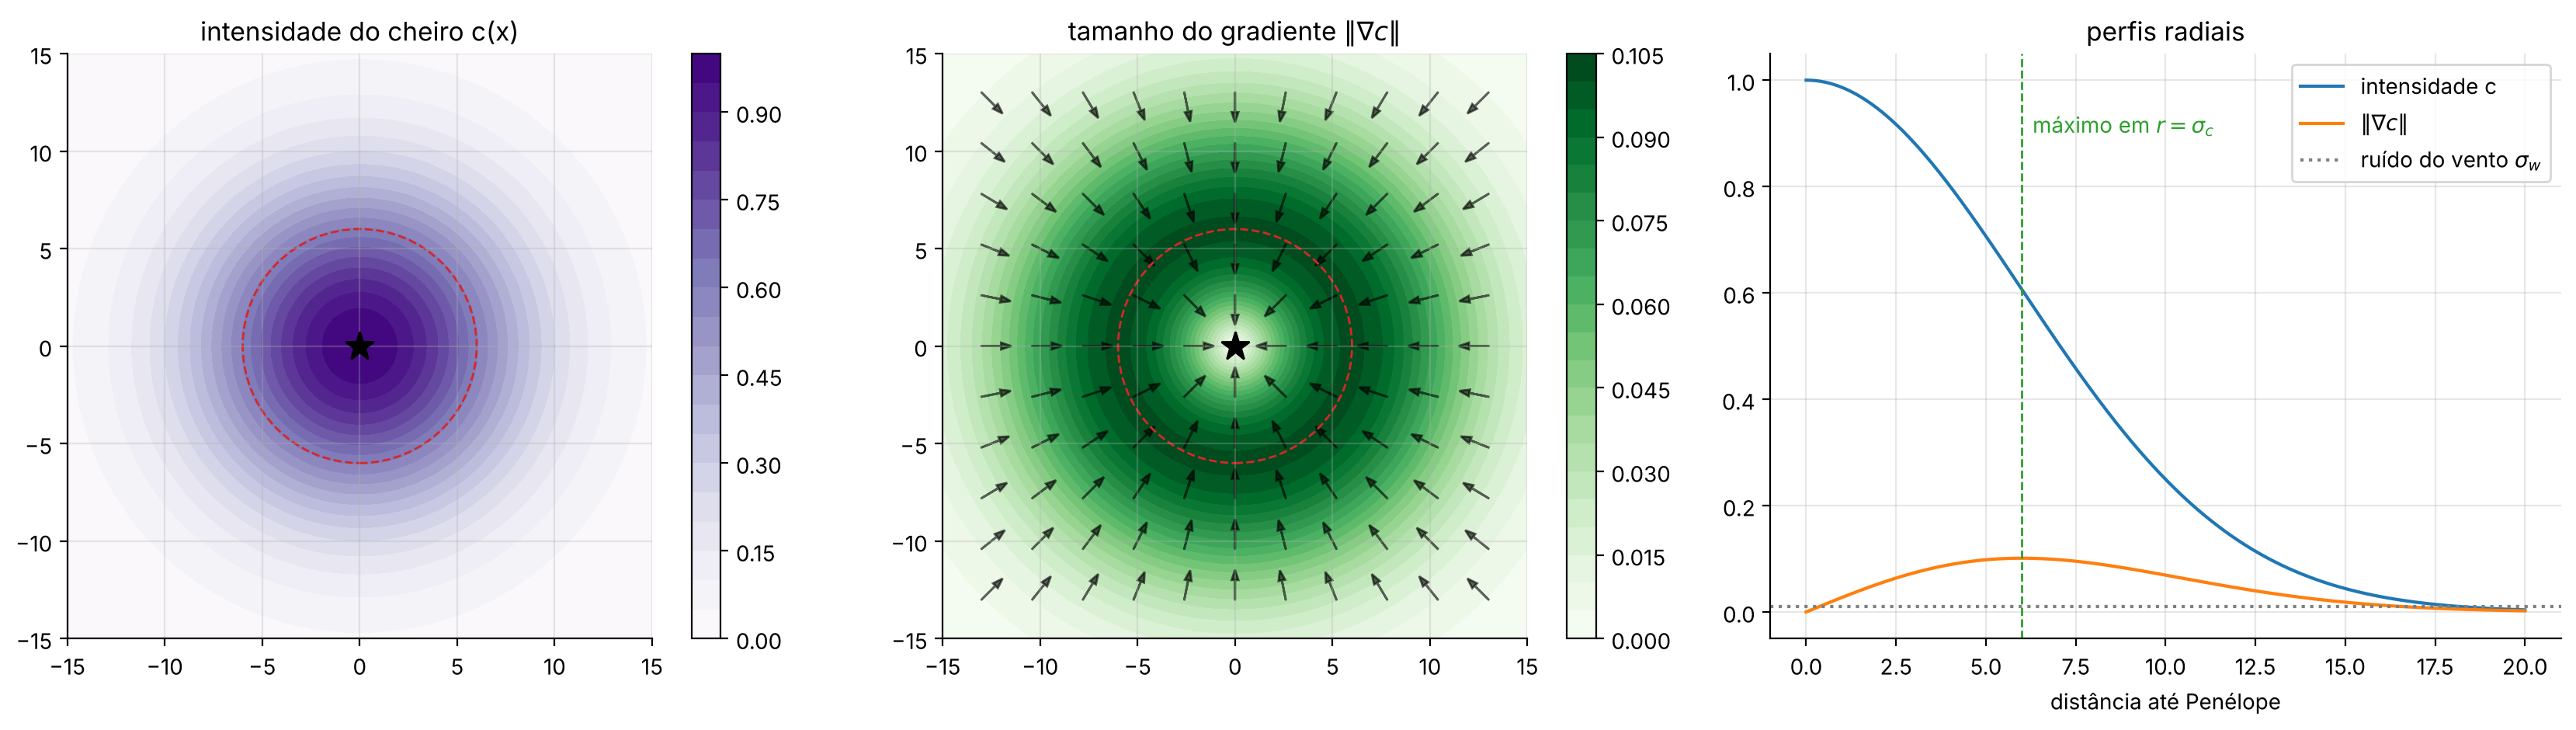

In [5]:
p_ex = np.array([0.0, 0.0])
g = np.linspace(-15, 15, 121); G1, G2 = np.meshgrid(g, g)
pts = np.c_[G1.ravel(), G2.ravel()]
C = np.array([cheiro(x, p_ex) for x in pts]).reshape(G1.shape)
GM = np.array([np.linalg.norm(grad_cheiro(x, p_ex)) for x in pts]).reshape(G1.shape)

fig, ax = plt.subplots(1, 3, figsize=(17, 4.8))
im = ax[0].contourf(G1, G2, C, 20, cmap="Purples"); plt.colorbar(im, ax=ax[0]); ax[0].set_title("intensidade do cheiro c(x)")
im = ax[1].contourf(G1, G2, GM, 20, cmap="Greens"); plt.colorbar(im, ax=ax[1]); ax[1].set_title(r"tamanho do gradiente $\|\nabla c\|$")
gq = np.linspace(-13, 13, 11)
for a in gq:
    for b in gq:
        v = grad_cheiro(np.array([a, b]), p_ex)
        if np.linalg.norm(v) > 0: ax[1].arrow(a, b, *(1.0 * v / np.linalg.norm(v)), head_width=.35, color="k", alpha=.6)
for a in ax[:2]:
    a.add_patch(Circle(p_ex, R_SOM, fill=False, ls="--", color="C3")); a.plot(*p_ex, "k*", ms=14); a.set_aspect("equal")
r = np.linspace(0, 20, 400)
ax[2].plot(r, A_C*np.exp(-r**2/(2*SIG_C**2)), label="intensidade c")
ax[2].plot(r, A_C*np.exp(-r**2/(2*SIG_C**2)) * r / SIG_C**2, label=r"$\|\nabla c\|$")
ax[2].axhline(SIG_W, color="gray", ls=":", label=r"ruído do vento $\sigma_w$")
ax[2].axvline(SIG_C, color="C2", ls="--", lw=1); ax[2].text(SIG_C + .3, .9, r"máximo em $r=\sigma_c$", color="C2")
ax[2].set_xlabel("distância até Penélope"); ax[2].legend(); ax[2].set_title("perfis radiais")
plt.tight_layout(); plt.show()

**O que observar.**

- **Painel do meio.** O gradiente tem um **anel** de máximo em $r=\sigma_c=6$. No centro e longe do centro, ele é fraco.
- **Painel da direita.** Para além de uns 18 unidades, o gradiente fica abaixo do ruído do vento: Pepé está "sem faro". A intensidade decai sempre (nunca volta a subir), por isso ela **resolve a ambiguidade de distância** que o gradiente tem. É o que vamos explorar na Fase 2.

---
# 2. O que Pepé quer aprender

Pepé quer saber onde Penélope está. Mas, para prever onde ela **estará**, também ajuda saber para onde e com que velocidade ela vai. O **estado** que ele estima tem 4 números:

$$s = (p_1,\ p_2,\ v_1,\ v_2)\qquad\text{(posição e velocidade de Penélope)}.$$

A posição do próprio Pepé, $x_P$, **não** faz parte do estado: ele sabe onde está.

## 2.1 Como Pepé acha que Penélope se move (o modelo de transição $F$, $Q$)

Pepé não sabe das regras de fuga. Ele usa um modelo simples e "humilde": **a velocidade se mantém, a menos de pequenas mudanças aleatórias**.

$$\begin{bmatrix}p\\v\end{bmatrix}_{t+1}=\underbrace{\begin{bmatrix}I&\Delta t\,I\\0&I\end{bmatrix}}_{F}\begin{bmatrix}p\\v\end{bmatrix}_t+w_t,\qquad w_t\sim\mathcal N(0,Q).$$

A primeira linha diz "posição nova = posição + velocidade × Δt", e a segunda, "velocidade nova = velocidade". O ruído $w_t$ representa mudanças de velocidade que ele não sabe prever. A matriz

$$Q=q\begin{bmatrix}\frac{\Delta t^3}{3}I & \frac{\Delta t^2}{2}I\\ \frac{\Delta t^2}{2}I & \Delta t\,I\end{bmatrix}$$

é a que resulta de supor acelerações aleatórias de intensidade $q$. **O número $q$ é a humildade de Pepé**: quanto maior, mais ele admite que Penélope pode mudar de velocidade de repente.

> **Ponto importante.** O modelo de Pepé **é diferente** do mundo real. Penélope alterna entre "parada" e "fugindo"; Pepé supõe velocidade quase constante. Todo modelo é uma simplificação. A Parte 2 (IMM) dará a Pepé um modelo com os dois modos.

## 2.2 Como Pepé acha que as medidas são geradas (o modelo de observação $h$)

As medidas dependem da posição de Penélope **e da posição de Pepé**. Na Fase 3, por exemplo,

$$h(s;\,x_P)=\big[\nabla c(x_P;p),\ c(x_P;p),\ \nabla s(x_P;p),\ s(x_P;p)\big]^\top .$$

Note que $h$ é **não linear** em $p$: exponenciais, quadrados, divisões. Por isso precisamos do **EKF**, a versão do Kalman que lineariza $h$ usando a sua derivada (o **jacobiano**). As medidas não dependem da velocidade, mas a velocidade é aprendida mesmo assim, através da correlação com a posição guardada em $P$: se ela "aparece" deslocada passo após passo, é porque está se movendo.

In [6]:
F = np.block([[np.eye(2), DT * np.eye(2)],
              [np.zeros((2, 2)), np.eye(2)]])

def Q_mat(q):
    return q * np.block([[DT**3 / 3 * np.eye(2), DT**2 / 2 * np.eye(2)],
                         [DT**2 / 2 * np.eye(2), DT * np.eye(2)]])

def h_modelo(s, xP, fase, ouviu):
    p = s[:2]
    partes = [grad_cheiro(xP, p)]
    if fase >= 2: partes.append([cheiro(xP, p)])
    if ouviu:     partes += [grad_som(xP, p), [som(xP, p)]]
    return np.concatenate(partes)

print("F =\n", F, "\nQ(q=1) =\n", Q_mat(1.0))

F =
 [[1.  0.  0.2 0. ]
 [0.  1.  0.  0.2]
 [0.  0.  1.  0. ]
 [0.  0.  0.  1. ]] 
Q(q=1) =
 [[0.0027 0.     0.02   0.    ]
 [0.     0.0027 0.     0.02  ]
 [0.02   0.     0.2    0.    ]
 [0.     0.02   0.     0.2   ]]


---
# 3. Jacobianos: as derivadas de que o filtro precisa

O EKF precisa da matriz $H=\partial h/\partial s$, com uma linha por medida e uma coluna por componente do estado. Como as medidas não dependem da velocidade, as duas últimas colunas são zero. Para as colunas da posição, com $d = x_P-p$, as contas dão:

| medida | derivada em relação a $p$ |
|---|---|
| gradiente do cheiro, $-\frac{c}{\sigma_c^2}d$ | $\frac{c}{\sigma_c^2}\Big(I-\frac{dd^\top}{\sigma_c^2}\Big)$ |
| intensidade do cheiro, $c$ | $\frac{c}{\sigma_c^2}\,d^\top$ |
| gradiente do som, $-\frac{2B}{D^2}d$, com $D=\|d\|^2+\varepsilon^2$ | $\frac{2B}{D^2}\Big(I-\frac{4dd^\top}{D}\Big)$ |
| intensidade do som, $B/D$ | $\frac{2B}{D^2}\,d^\top$ |

Contas à mão erram com facilidade. Conferimos cada uma pela **derivada de passo complexo**: para uma função analítica $f$,

$$f'(x)\approx\frac{\operatorname{Im} f(x+i\,h)}{h},$$

com $h=10^{-20}$. Diferente das diferenças finitas, não há subtração de números próximos, logo nenhum erro de cancelamento: o resultado é exato até a precisão da máquina. Funciona porque todas as nossas funções usam só operações analíticas (`exp`, `@`, divisão).

In [7]:
def J_modelo(s, xP, fase, ouviu):
    p = s[:2]; d = xP - p; c = cheiro(xP, p)
    linhas = [c / SIG_C**2 * (np.eye(2) - np.outer(d, d) / SIG_C**2)]
    if fase >= 2:
        linhas.append((c * d / SIG_C**2)[None, :])
    if ouviu:
        D = d @ d + EPS_S**2
        linhas.append(2 * B_S / D**2 * (np.eye(2) - 4 * np.outer(d, d) / D))
        linhas.append((2 * B_S * d / D**2)[None, :])
    Jp = np.vstack(linhas)
    return np.hstack([Jp, np.zeros_like(Jp)])          # colunas da velocidade: zero

def J_passo_complexo(s, xP, fase, ouviu, h=1e-20):
    colunas = []
    for j in range(len(s)):
        e = np.zeros(len(s), complex); e[j] = 1j * h
        colunas.append(np.imag(h_modelo(s + e, xP, fase, ouviu)) / h)
    return np.array(colunas).T

s_teste, xP_teste = np.array([3.0, -2.0, 0.5, 0.1]), np.array([1.0, 1.5])
for fase, ouviu in [(1, False), (2, False), (3, True)]:
    confere(f"jacobiano analítico = passo complexo (fase {fase})",
            J_modelo(s_teste, xP_teste, fase, ouviu), J_passo_complexo(s_teste, xP_teste, fase, ouviu), tol=1e-12)
print("\nformato de H na fase 3 (ouvindo):", J_modelo(s_teste, xP_teste, 3, True).shape, " → 6 medidas × 4 estados")

OK   jacobiano analítico = passo complexo (fase 1):  diferença máxima = 5.20e-18
OK   jacobiano analítico = passo complexo (fase 2):  diferença máxima = 1.39e-17
OK   jacobiano analítico = passo complexo (fase 3):  diferença máxima = 1.39e-17

formato de H na fase 3 (ouvindo): (6, 4)  → 6 medidas × 4 estados


---
# 4. EKF e Kalman iterado

A atualização é a do Kalman, com uma diferença: como $h$ é curva, ela é **aproximada por uma reta** (a sua tangente, dada pelo jacobiano) num ponto escolhido.

- **EKF**: lineariza **uma vez**, na previsão $m^-$.
- **Kalman iterado (IEKF)**: lineariza, corrige, **relineariza no novo ponto**, corrige de novo... até parar de mudar. Cada iteração é **um passo do método de Gauss–Newton** para minimizar

$$\chi^2(s)=(s-m^-)^\top (P^-)^{-1}(s-m^-) + (z-h(s))^\top R^{-1}(z-h(s)),$$

ou seja, "não se afastar demais do que eu previa" mais "explicar bem as medidas". É o mesmo tipo de função de custo de um problema de aprendizado com regularização: **o *prior* é o regularizador e as medidas são os dados**. A fórmula é a de Bell & Cathey (1993):

$$s_{j+1}=m^-+K_j\big(z-h(s_j)-H_j\,(m^--s_j)\big),\qquad K_j=P^-H_j^\top\big(H_jP^-H_j^\top+R\big)^{-1}.$$

Com uma iteração ($s_0=m^-$), ela é exatamente o EKF.

In [8]:
def atualizacao(m, P, z, R, h, J, n_iter=1, tol=1e-9):
    # EKF (n_iter = 1) ou Kalman iterado (n_iter > 1). Devolve também o histórico das iterações.
    s, iters = m.copy(), [m.copy()]
    for _ in range(n_iter):
        H = J(s); S = H @ P @ H.T + R
        K = np.linalg.solve(S, H @ P).T
        s_novo = m + K @ (z - h(s) - H @ (m - s))
        iters.append(s_novo)
        if np.linalg.norm(s_novo - s) < tol: s = s_novo; break
        s = s_novo
    H = J(s); S = H @ P @ H.T + R; K = np.linalg.solve(S, H @ P).T
    P_novo = P - K @ S @ K.T
    return s, (P_novo + P_novo.T) / 2, K, np.array(iters)

A **simulação completa** junta tudo. A cada passo:

1. Penélope se move (`passo_penelope`);
2. Pepé mede (`mede`);
3. Pepé **prevê** onde ela deveria estar (predição do Kalman) e **corrige** com a medida (atualização);
4. Pepé dá um passo:
   - na estratégia `"kalman"`, em direção à posição **estimada** $m_{1:2}$;
   - na estratégia `"ingenuo"`, na direção do **gradiente medido**, sem filtro algum. Isso é o que fazem bactérias seguindo um gradiente químico (quimiotaxia).

**O *prior*.** Pepé começa na origem sem saber onde Penélope está. A crença inicial é $m_0=(0,0,0,0)$, centrada nele mesmo, com desvio-padrão 8 na posição e 1 na velocidade. Penélope começa a 15 unidades, numa direção sorteada.

A função guarda tudo o que acontece, para os gráficos e os quadros.

In [9]:
def simula(estrategia="kalman", fase=1, seed=0, n_iter=1, q=1.0,
           P0=np.diag([64.0, 64.0, 1.0, 1.0]), m0=np.zeros(4)):
    rng = np.random.default_rng(seed)
    ang0 = rng.uniform(0, 2 * np.pi)
    pen = dict(p=15 * np.array([np.cos(ang0), np.sin(ang0)]), v=np.zeros(2),
               fugindo=False, t_restante=0.0, gatilho=rng.uniform(2.0, 4.5))
    xP, m, P, Q = np.zeros(2), m0.astype(float).copy(), P0.astype(float).copy(), Q_mat(q)
    reg = []
    for k in range(N_PASSOS):
        pen = passo_penelope(pen, xP, rng)
        z, R, ouviu = mede(xP, pen["p"], fase, rng)
        m_ant, P_ant = m.copy(), P.copy()
        if k > 0: m, P = F @ m, F @ P @ F.T + Q                        # predição
        m_pred, P_pred = m.copy(), P.copy()
        h = lambda s: h_modelo(s, xP, fase, ouviu)
        J = lambda s: J_modelo(s, xP, fase, ouviu)
        m, P, K, iters = atualizacao(m, P, z, R, h, J, n_iter)            # atualização
        reg.append(dict(k=k, t=k * DT, xP=xP.copy(), p=pen["p"].copy(), v=pen["v"].copy(),
                        fugindo=pen["fugindo"], ouviu=ouviu, z=z, R=R, h_pred=h(m_pred),
                        m_ant=m_ant, P_ant=P_ant, m_pred=m_pred, P_pred=P_pred, K=K, iters=iters, m=m.copy(), P=P.copy()))
        direcao = z[:2] if estrategia == "ingenuo" else m[:2] - xP          # Pepé decide para onde andar
        if np.linalg.norm(direcao) > 1e-12:
            xP = xP + V_PEPE * DT * direcao / np.linalg.norm(direcao)
    return reg

def series(reg):
    # extrai séries temporais úteis de um registro
    t = np.array([r["t"] for r in reg])
    erro = np.array([np.linalg.norm(r["m"][:2] - r["p"]) for r in reg])
    sd_pos = np.array([np.sqrt(np.trace(r["P"][:2, :2])) for r in reg])
    dist = np.array([np.linalg.norm(r["xP"] - r["p"]) for r in reg])
    fug = np.array([r["fugindo"] for r in reg]); ouv = np.array([r["ouviu"] for r in reg])
    nees = np.array([(r["m"][:2] - r["p"]) @ np.linalg.solve(r["P"][:2, :2], r["m"][:2] - r["p"]) for r in reg])
    return dict(t=t, erro=erro, sd=sd_pos, dist=dist, fugindo=fug, ouviu=ouv, nees=nees)

Uma função de desenho para a arena, reaproveitada por todo o notebook:

- **fundo roxo**: o cheiro **real** naquele instante (Pepé não o vê; é só para nós);
- **estrela preta**: Penélope (escondida); a linha cinza é o caminho dela;
- **triângulo roxo**: Pepé; a linha roxa é o caminho dele;
- **ponto vermelho com elipse**: onde Pepé **acha** que ela está, com a elipse de 2 desvios-padrão (região de ~86% de confiança em 2D);
- **seta verde**: a direção do gradiente medido pelo nariz;
- **círculo tracejado**: o alcance do som em volta de Penélope.

In [10]:
def elipse(ax, centro, Ppos, k=2.0, **kw):
    w, V = np.linalg.eigh(Ppos)
    ang = np.degrees(np.arctan2(V[1, -1], V[0, -1]))
    ax.add_patch(Ellipse(centro, 2 * k * np.sqrt(w[-1]), 2 * k * np.sqrt(w[0]), angle=ang, fill=False, **kw))

def desenha_arena(ax, reg, k, titulo="", mostra_som=False, janela=None):
    r = reg[k]
    caminhoP = np.array([x["xP"] for x in reg[:k + 1]]); caminhoPen = np.array([x["p"] for x in reg[:k + 1]])
    est = np.array([x["m"][:2] for x in reg[:k + 1]])
    cx, cy = (r["xP"] + r["p"]) / 2 if janela is None else janela[:2]
    L = max(10, 0.75 * np.linalg.norm(r["xP"] - r["p"]) + 6, np.linalg.norm(r["m"][:2] - r["xP"]) * 0.6 + 4) if janela is None else janela[2]
    g1, g2 = np.meshgrid(np.linspace(cx - L, cx + L, 90), np.linspace(cy - L, cy + L, 90))
    Cf = A_C * np.exp(-((g1 - r["p"][0])**2 + (g2 - r["p"][1])**2) / (2 * SIG_C**2))
    ax.contourf(g1, g2, Cf, 15, cmap="Purples", alpha=.35)
    ax.plot(*caminhoPen.T, color="gray", lw=1, ls="--"); ax.plot(*r["p"], "k*", ms=16, label="Penélope (escondida)")
    ax.plot(*caminhoP.T, color="C4", lw=1.5); ax.plot(*r["xP"], "^", color="C4", ms=12, label="Pepé")
    ax.plot(*est.T, color="C3", lw=1, alpha=.6); ax.plot(*r["m"][:2], "o", color="C3", ms=7, label="estimativa de Pepé")
    elipse(ax, r["m"][:2], r["P"][:2, :2], color="C3", lw=2)
    g = r["z"][:2]
    if np.linalg.norm(g) > 0:
        ax.annotate("", xy=r["xP"] + 3 * g / np.linalg.norm(g), xytext=r["xP"],
                    arrowprops=dict(arrowstyle="->", color="C2", lw=2.5))
    if mostra_som: ax.add_patch(Circle(r["p"], R_SOM, fill=False, ls=":", color="C1", lw=1.5))
    ax.set_xlim(cx - L, cx + L); ax.set_ylim(cy - L, cy + L); ax.set_aspect("equal")
    ax.set_title(titulo, fontsize=10)

---
# 5. Fase 1: o nariz mede só o gradiente

Começamos pelo cenário mais difícil, comparando três Pepés **na mesma situação inicial** (mesma semente):

- o **ingênuo**, que segue o gradiente medido;
- o **EKF**;
- o **Kalman iterado** (até 10 iterações por passo).

A semente fixa o mundo inicial. Como Pepé se move diferente em cada estratégia, Penélope também reage diferente, e as histórias divergem depois da primeira fuga.

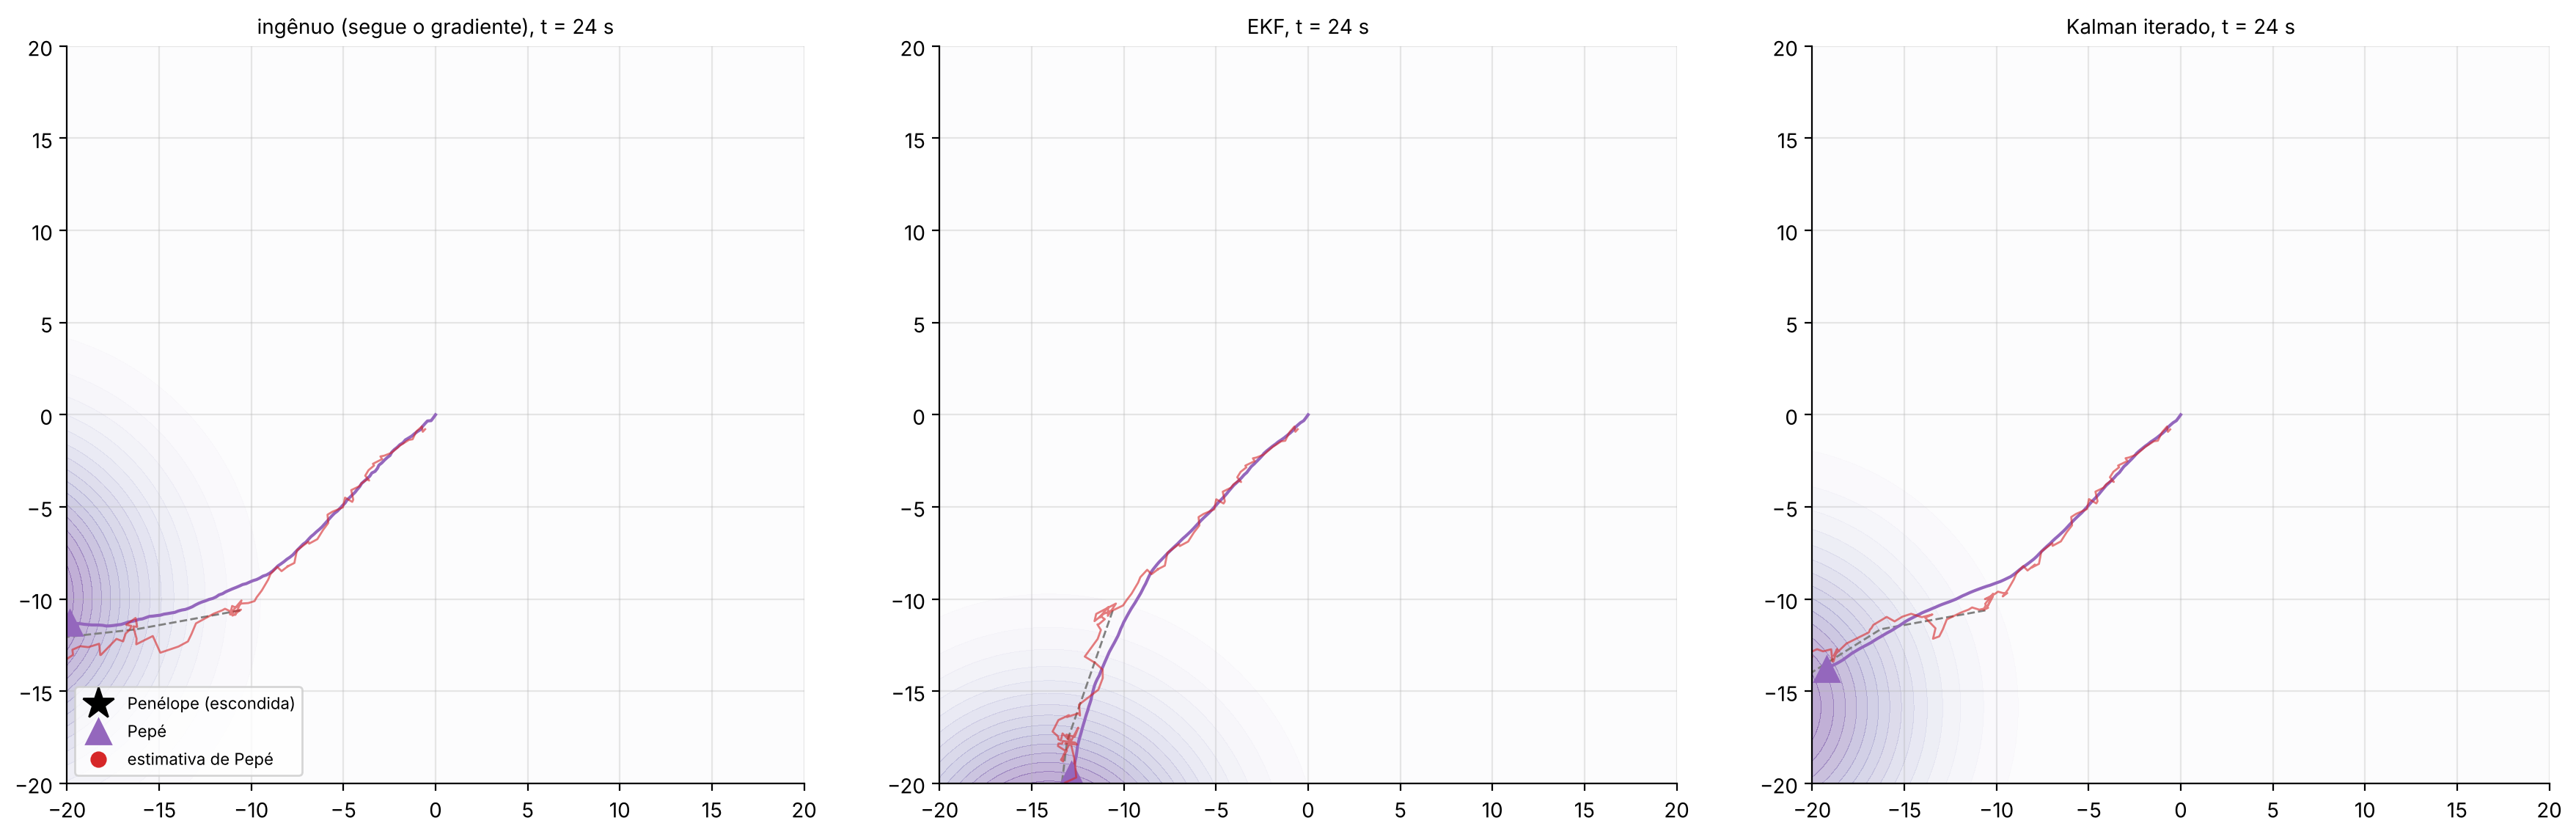

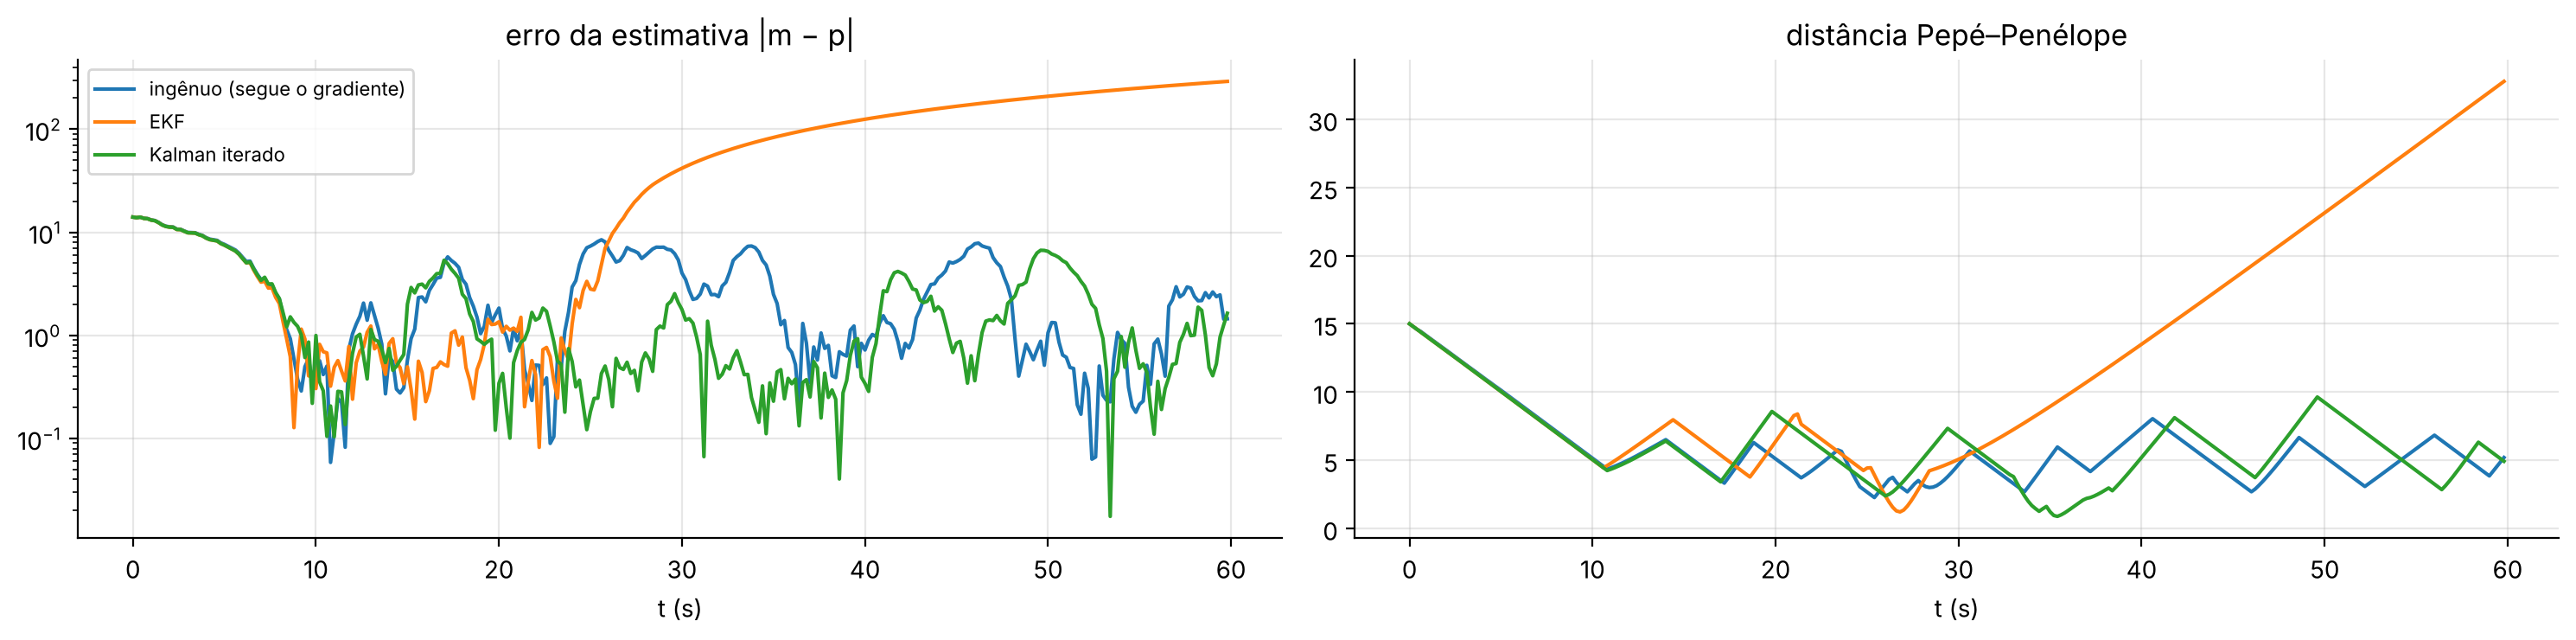

In [11]:
SEED = 7
casos_f1 = {"ingênuo (segue o gradiente)": simula("ingenuo", 1, SEED),
            "EKF": simula("kalman", 1, SEED, n_iter=1),
            "Kalman iterado": simula("kalman", 1, SEED, n_iter=10)}

fig, ax = plt.subplots(1, 3, figsize=(18, 5.6))
for a, (nome, reg) in zip(ax, casos_f1.items()):
    desenha_arena(a, reg, 120, f"{nome}, t = {reg[120]['t']:.0f} s", janela=(0, 0, 20))
ax[0].legend(loc="lower left", fontsize=8); plt.tight_layout(); plt.show()

fig, ax = plt.subplots(1, 2, figsize=(15, 3.8))
for nome, reg in casos_f1.items():
    S_ = series(reg)
    ax[0].plot(S_["t"], S_["erro"], label=nome); ax[1].plot(S_["t"], S_["dist"], label=nome)
ax[0].set_yscale("log"); ax[0].set_title("erro da estimativa |m − p|"); ax[0].set_xlabel("t (s)"); ax[0].legend(fontsize=8)
ax[1].set_title("distância Pepé–Penélope"); ax[1].set_xlabel("t (s)")
plt.tight_layout(); plt.show()

**O que observar.**

- **A elipse é alongada.** Ela é estreita na direção perpendicular à linha Pepé–Penélope e comprida ao longo dela. O gradiente diz bem a **direção** de Penélope, mas mal a **distância**. É a ambiguidade da seção 1.
- **O Pepé ingênuo persegue razoavelmente bem.** Para **perseguir**, a direção basta. O que o filtro acrescenta é **saber onde ela está** e **com que certeza**. No caso do ingênuo, um EKF roda "de carona" só para medirmos o erro; Pepé ignora a estimativa e segue o gradiente.
- **O Kalman iterado erra menos que o EKF.** Quando a linearização num ponto ruim engana, iterar corrige.

# 6. Fase 2: gradiente e intensidade

A intensidade $c$ cai sempre com a distância. Sozinha, ela diz "estou a mais ou menos tal distância", e **não** diz a direção. O gradiente diz a direção e não a distância. **Juntas, as duas medidas se completam.** É a primeira lição de integração de sensores.

Mas há um perigo. A intensidade é **muito** não linear: perto de Pepé ela vale quase 1, longe vale quase 0. E o *prior* de Pepé está centrado **nele mesmo**, onde ela vale exatamente 1 e o jacobiano da intensidade é zero (é o topo da gaussiana). A primeira medida diz "intensidade 0,04" e o modelo linearizado prevê "1". Vejamos o que cada filtro faz com essa surpresa enorme.

Penélope (parada) está em [-10.6002 -10.613 ]
Primeira medida z = [∂c/∂x1, ∂c/∂x2, c] = [-0.0157 -0.0219  0.0348];  previsto no prior h(m⁻) = [-0. -0.  1.]

                      p1 estimado  p2 estimado  v1 estimado  v2 estimado  desvio-padrão de p1  erro |m − p|
filtro         t (s)                                                                                       
EKF            0.0         -0.563       -0.785        0.000        0.000                0.355        14.047
               0.2         -2.689       -3.336       -2.986       -3.644                0.267        10.749
               0.4         -6.182       -7.552      -10.796      -13.121                0.339         5.375
               0.6         -8.767      -10.690      -11.829      -14.369                0.482         1.835
               1.0        -13.280      -16.135      -11.500      -13.930                0.866         6.138
               2.0        -24.675      -29.926      -11.432      -13.842               

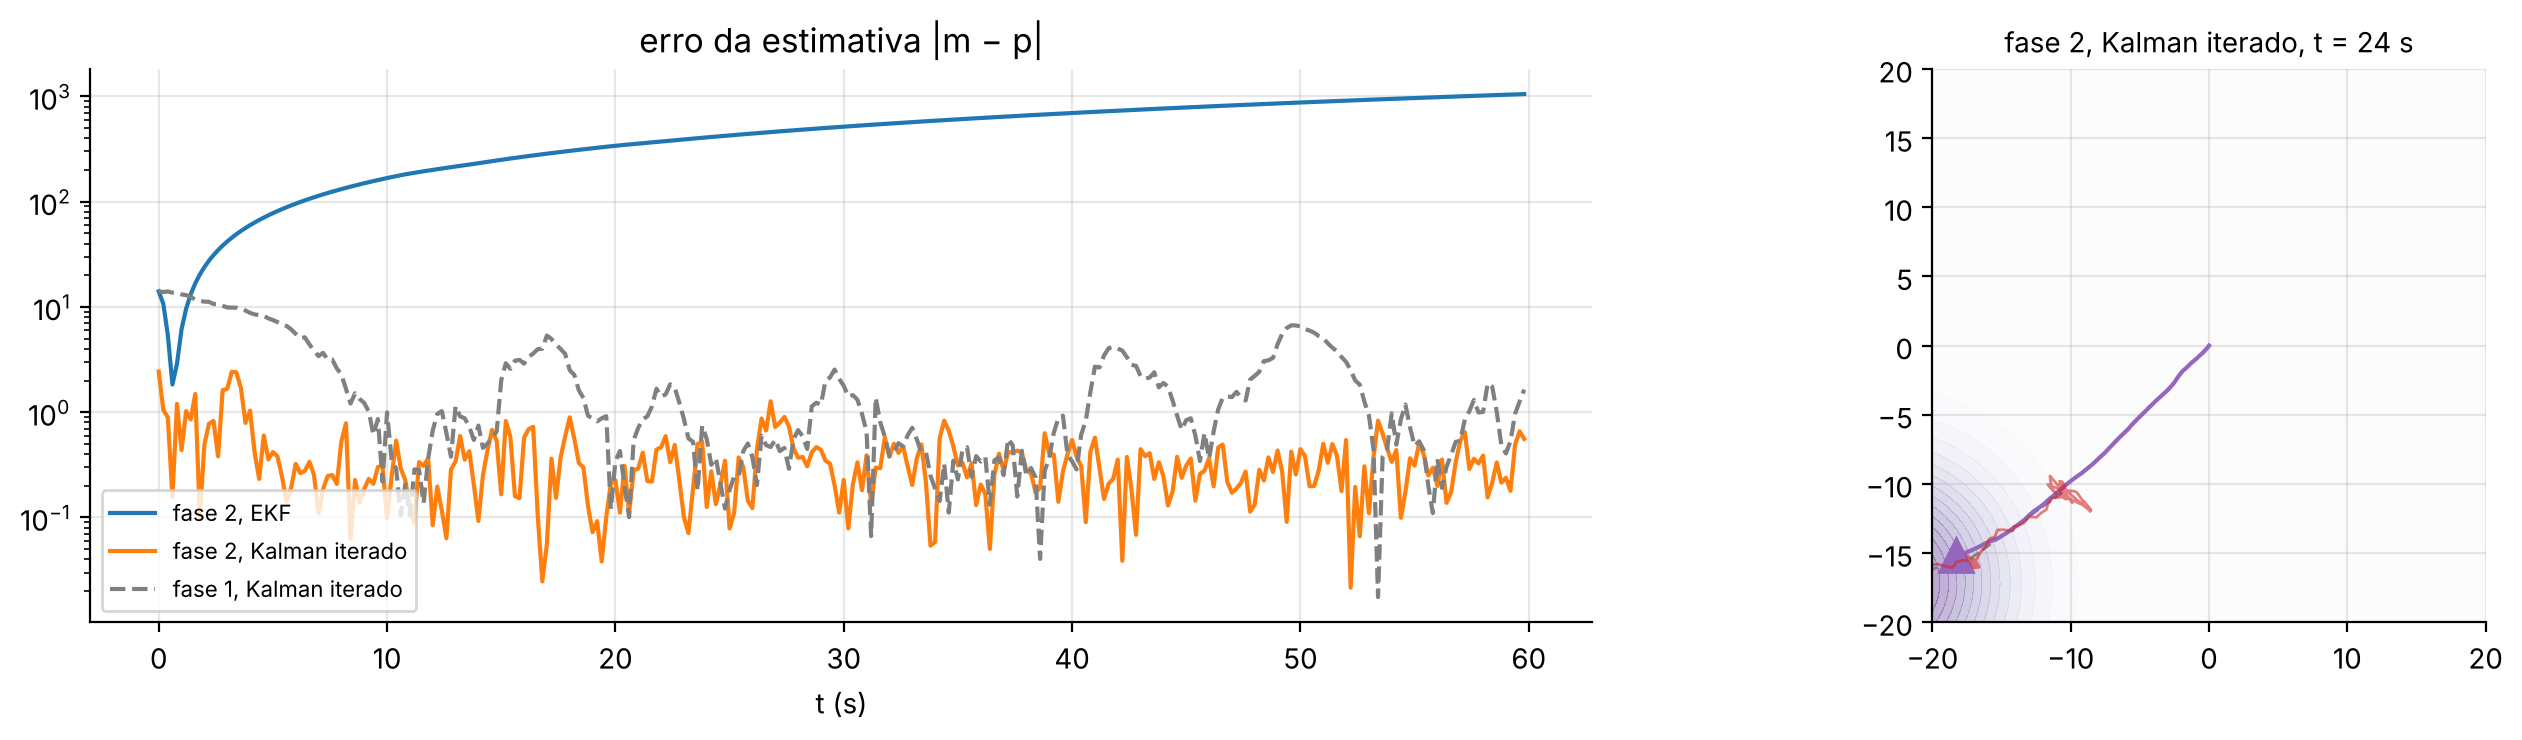

In [12]:
casos_f2 = {"EKF": simula("kalman", 2, SEED, n_iter=1),
            "Kalman iterado": simula("kalman", 2, SEED, n_iter=10)}

r0 = casos_f2["EKF"][0]
print(f"Penélope (parada) está em {r0['p']}")
print(f"Primeira medida z = [∂c/∂x1, ∂c/∂x2, c] = {r0['z']};  previsto no prior h(m⁻) = {r0['h_pred']}\n")
linhas = []
for nome, reg in casos_f2.items():
    for k in [0, 1, 2, 3, 5, 10, 20]:
        r = reg[k]
        linhas.append({"filtro": nome, "t (s)": r["t"], "p1 estimado": r["m"][0], "p2 estimado": r["m"][1],
                       "v1 estimado": r["m"][2], "v2 estimado": r["m"][3],
                       "desvio-padrão de p1": np.sqrt(r["P"][0, 0]), "erro |m − p|": np.linalg.norm(r["m"][:2] - r["p"])})
print(pd.DataFrame(linhas).set_index(["filtro", "t (s)"]).to_string())

fig, ax = plt.subplots(1, 2, figsize=(15, 3.8))
for nome, reg in casos_f2.items():
    S_ = series(reg); ax[0].plot(S_["t"], S_["erro"], label=f"fase 2, {nome}")
S_ = series(casos_f1["Kalman iterado"]); ax[0].plot(S_["t"], S_["erro"], "--", color="gray", label="fase 1, Kalman iterado")
ax[0].set_yscale("log"); ax[0].set_title("erro da estimativa |m − p|"); ax[0].set_xlabel("t (s)"); ax[0].legend(fontsize=8)
desenha_arena(ax[1], casos_f2["Kalman iterado"], 120, "fase 2, Kalman iterado, t = 24 s", janela=(0, 0, 20))
plt.tight_layout(); plt.show()

**O que observar.**

- **O EKF fica confiante demais logo no primeiro passo.** Linearizado no topo da gaussiana, ele mal sai do lugar (anda menos de 1 unidade em direção a Penélope, que está a 15), mas o desvio-padrão despenca de 8 para cerca de 0,35. Ele **acha que sabe** onde ela está e está errado. É o mesmo fenômeno do exemplo de Bell & Cathey: **um único passo de Newton, num ponto ruim, com certeza demais**.
- **Depois, o EKF inventa um movimento.** Com a posição "travada" pela confiança excessiva, a única forma de explicar as medidas seguintes, que continuam dizendo "ela está mais longe", é supor que **Penélope está correndo**. A velocidade estimada cresce, a estimativa passa do ponto e segue em frente. Longe de tudo, cheiro e gradiente previstos valem zero, as medidas param de informar, e o filtro nunca mais volta.
- **O Kalman iterado faz o que se esperava.** Com a intensidade, o erro fica bem menor que na Fase 1 e a elipse fica pequena e redonda.

Lição para levar: **acrescentar um sensor bom ajuda, desde que o filtro saiba lidar com a não linearidade dele**. Daqui em diante usamos sempre o Kalman iterado.

---
# 7. Fase 3: os ouvidos, e o que é integração de sensores

Quando Pepé chega a menos de $R_{som}=6$ de Penélope, o vetor de medidas ganha mais 3 componentes (gradiente e intensidade do som). Nada no algoritmo muda: `h`, `H` e `R` simplesmente ficam maiores.

## 7.1 Integrar sensores é somar informação

Para entender por que isso funciona, volte à forma de informação do Kalman. Se os sensores têm ruídos **independentes**, cada um com sua matriz $H_i$ e seu $R_i$, a precisão posterior é

$$P^{-1}=(P^-)^{-1}+\sum_{i}H_i^\top R_i^{-1}H_i .$$

Cada sensor **soma** a sua parcela de informação, e o resultado não depende da ordem. Na linguagem de aprendizado de máquina: a função de custo $\chi^2$ é uma **soma de perdas**, uma por sensor, cada uma **ponderada pelo inverso da variância do ruído**. Um sensor preciso pesa muito; um sensor ruidoso, pouco. É a mesma ideia de combinar estimadores independentes por média ponderada pelo inverso da variância.

Há duas maneiras equivalentes de implementar isso:

1. **empilhar** todas as medidas num vetor só, com $R$ bloco-diagonal (o que a função `mede` faz);
2. atualizar **sequencialmente**: primeiro com o nariz, depois, partindo do resultado, com os ouvidos.

Conferimos que as duas dão o mesmo resultado, e que a precisão final é a soma das informações. Para que a conferência seja exata, linearizamos todos os sensores no mesmo ponto: o caso linear.

In [13]:
reg3 = simula("kalman", 3, SEED, n_iter=10)
k_ouve = next(r["k"] for r in reg3 if r["ouviu"])
r = reg3[k_ouve]
m_, P_ = r["m_pred"], r["P_pred"]
H_all = J_modelo(m_, r["xP"], 3, True); R_all = r["R"]
nariz, ouvido = slice(0, 3), slice(3, 6)

def atualiza_linear(m, P, z, H, R):
    S = H @ P @ H.T + R; K = np.linalg.solve(S, H @ P).T
    return m + K @ (z - H @ m), P - K @ S @ K.T

z_lin = H_all @ m_ + (r["z"] - r["h_pred"])                   # medida "linearizada" em m⁻
m_emp, P_emp = atualiza_linear(m_, P_, z_lin, H_all, R_all)
m_1, P_1 = atualiza_linear(m_, P_, z_lin[nariz], H_all[nariz], R_all[nariz, nariz])
m_seq, P_seq = atualiza_linear(m_1, P_1, z_lin[ouvido], H_all[ouvido], R_all[ouvido, ouvido])
info = np.linalg.inv(P_) + sum(H_all[s_].T @ np.linalg.inv(R_all[s_, s_]) @ H_all[s_] for s_ in (nariz, ouvido))
print(f"instante t = {r['t']:.1f} s: Pepé começa a ouvir o coração\n")
confere("empilhar = atualizar em sequência (média)", m_emp, m_seq, tol=1e-9)
confere("empilhar = atualizar em sequência (covariância)", P_emp, P_seq, tol=1e-9)
confere("P⁻¹ = (P⁻)⁻¹ + Σ Hᵢᵀ Rᵢ⁻¹ Hᵢ", np.linalg.inv(P_emp), info, tol=1e-6 * np.abs(info).max())

instante t = 9.2 s: Pepé começa a ouvir o coração

OK   empilhar = atualizar em sequência (média):  diferença máxima = 1.01e-15
OK   empilhar = atualizar em sequência (covariância):  diferença máxima = 1.11e-16
OK   P⁻¹ = (P⁻)⁻¹ + Σ Hᵢᵀ Rᵢ⁻¹ Hᵢ:  diferença máxima = 2.84e-14


## 7.2 Cada sensor encolhe a elipse numa direção diferente

No mesmo instante, desenhamos a elipse de incerteza da posição (o bloco $2\times2$ de $P$):

1. só com a predição;
2. depois do gradiente do cheiro;
3. depois de somar a intensidade do cheiro;
4. depois de somar o som.

Usamos a forma de informação acima: cada sensor é só mais uma parcela na soma.

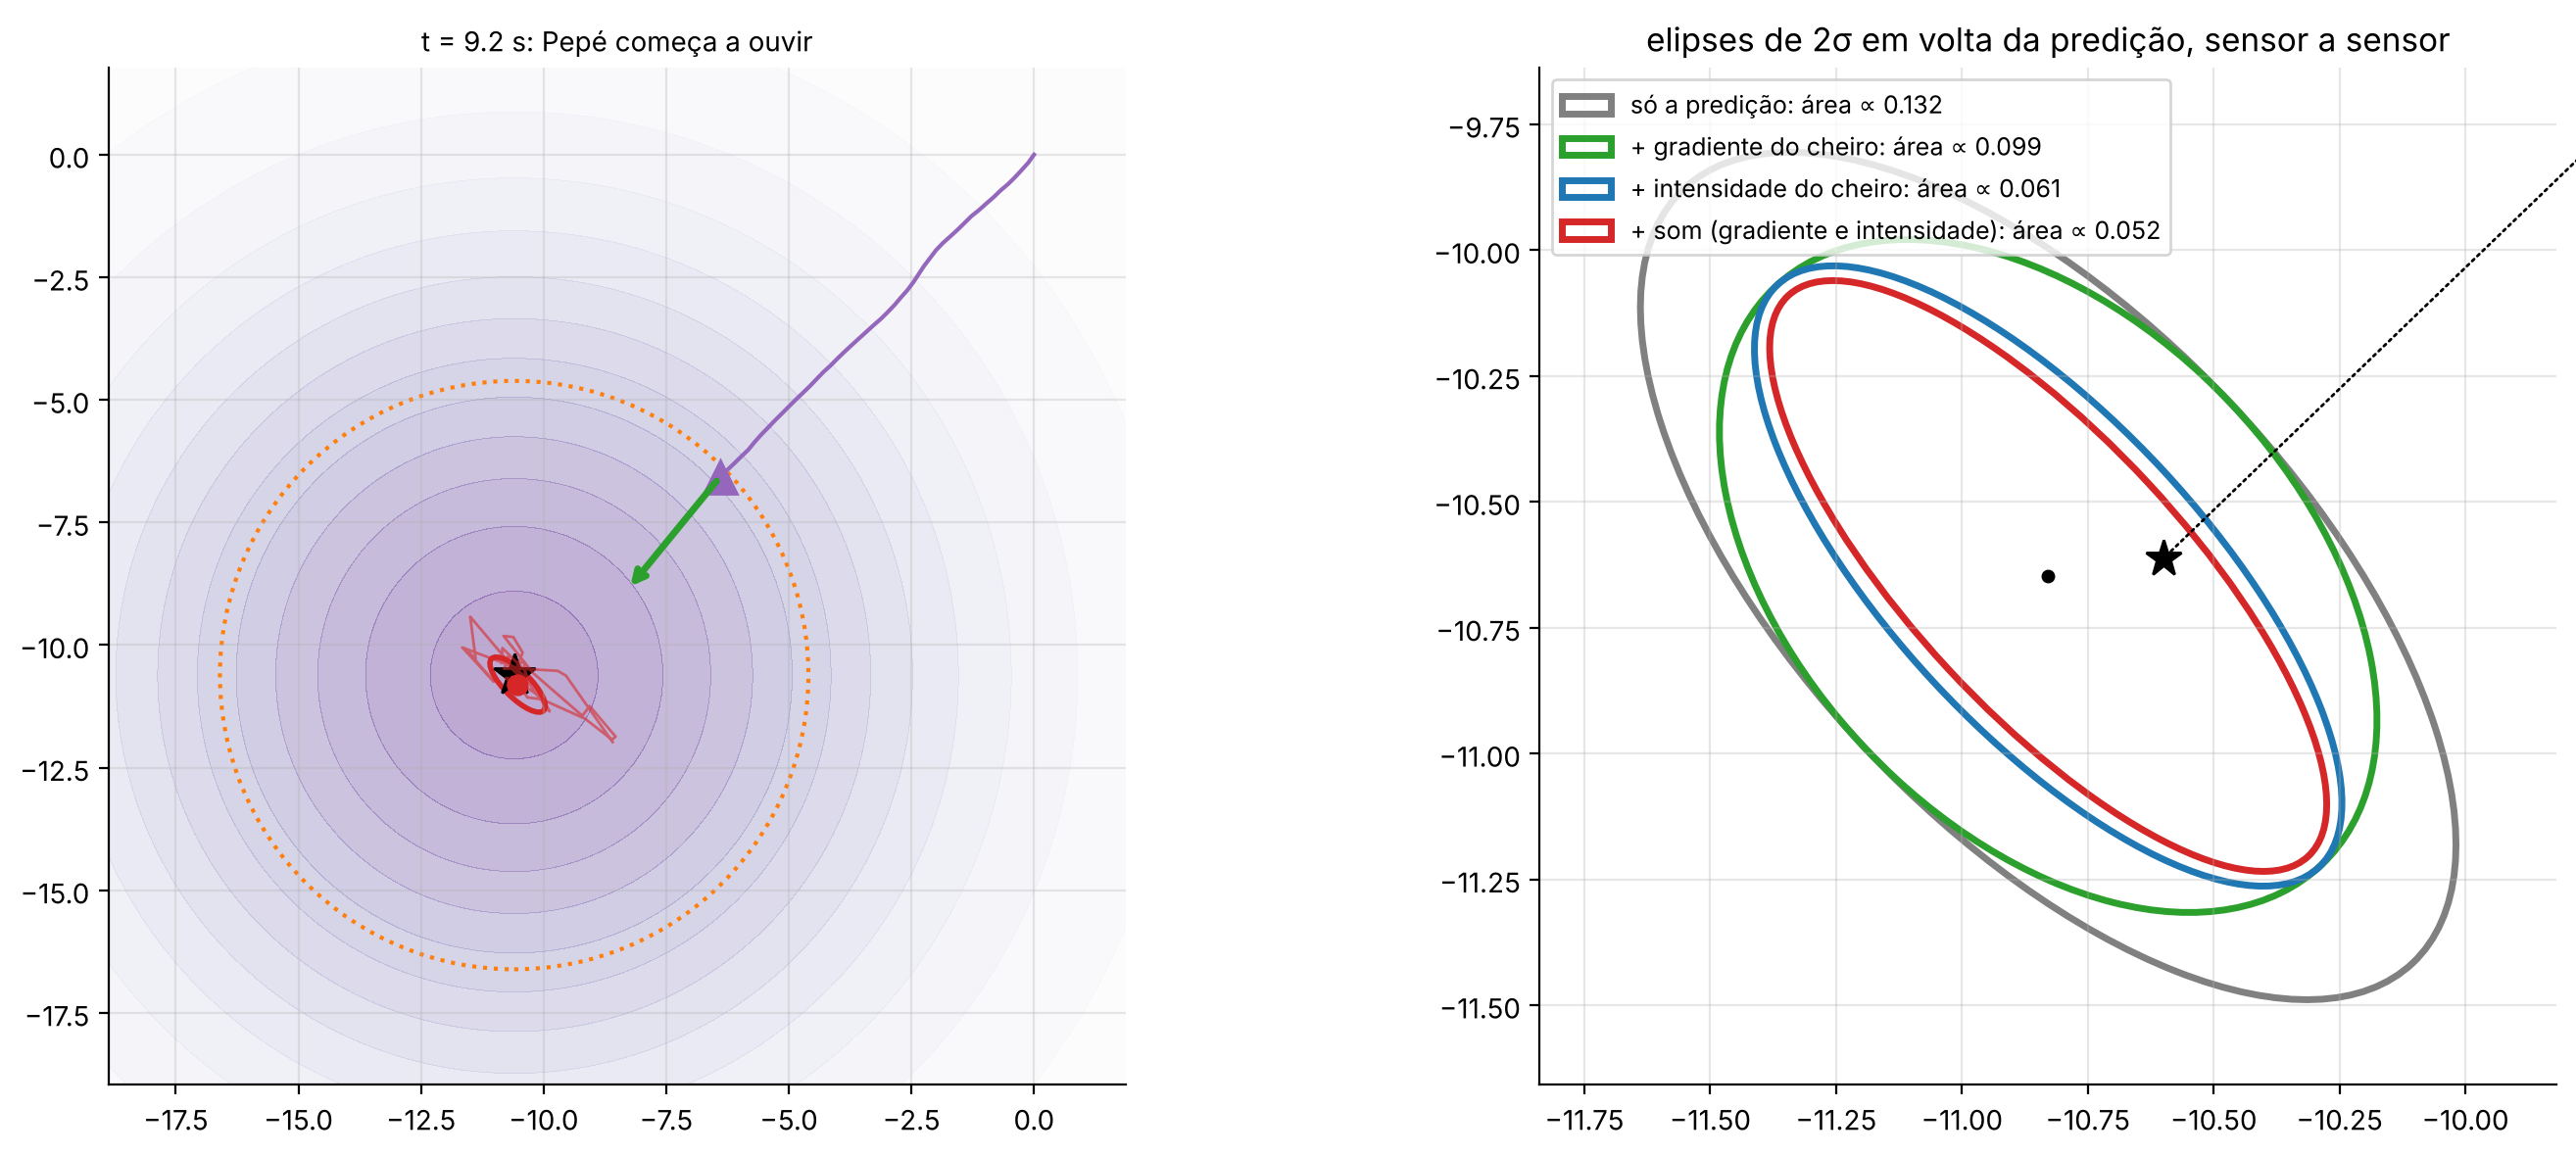

In [14]:
def P_com(blocos):
    I_ = np.linalg.inv(P_) + sum(H_all[b].T @ np.linalg.inv(R_all[b, b]) @ H_all[b] for b in blocos)
    return np.linalg.inv(I_)

etapas = [("só a predição", []),
          ("+ gradiente do cheiro", [slice(0, 2)]),
          ("+ intensidade do cheiro", [slice(0, 2), slice(2, 3)]),
          ("+ som (gradiente e intensidade)", [slice(0, 2), slice(2, 3), slice(3, 6)])]
fig, ax = plt.subplots(1, 2, figsize=(15, 6))
desenha_arena(ax[0], reg3, k_ouve, f"t = {r['t']:.1f} s: Pepé começa a ouvir", mostra_som=True)
for (nome, blocos), cor in zip(etapas, ["gray", "C2", "C0", "C3"]):
    Pp = P_com(blocos)[:2, :2]
    elipse(ax[1], m_[:2], Pp, color=cor, lw=2.5, label=f"{nome}: área ∝ {np.sqrt(np.linalg.det(Pp)):.3f}")
ax[1].plot(*r["xP"], "^", color="C4", ms=12); ax[1].plot(*r["p"], "k*", ms=14); ax[1].plot(*m_[:2], "o", color="k", ms=4)
ax[1].annotate("", xy=r["p"], xytext=r["xP"], arrowprops=dict(arrowstyle="-", ls=":", color="k"))
sd0 = np.sqrt(P_[:2, :2].max()) * 2.4
ax[1].set_xlim(m_[0] - sd0, m_[0] + sd0); ax[1].set_ylim(m_[1] - sd0, m_[1] + sd0); ax[1].set_aspect("equal")
ax[1].legend(fontsize=9, loc="upper left"); ax[1].set_title("elipses de 2σ em volta da predição, sensor a sensor")
plt.tight_layout(); plt.show()

Para não depender só do olho, medimos **quanta informação cada sensor traz em cada direção**. Para um sensor com $H_i$ e $R_i$, a informação na direção unitária $u$ é $u^\top H_i^\top R_i^{-1}H_i\,u$. Usamos duas direções: a **radial** (ao longo da linha Pepé–Penélope, ou seja, a distância) e a **tangencial** (perpendicular a ela, ou seja, a direção).

In [15]:
u_rad = r["xP"] - m_[:2]; dist_ = np.linalg.norm(u_rad); u_rad /= dist_
u_tan = np.array([-u_rad[1], u_rad[0]])
linhas = []
for nome, b in [("gradiente do cheiro", slice(0, 2)), ("intensidade do cheiro", slice(2, 3)),
                ("gradiente do som", slice(3, 5)), ("intensidade do som", slice(5, 6))]:
    I_ = H_all[b][:, :2].T @ np.linalg.inv(R_all[b, b]) @ H_all[b][:, :2]
    linhas.append({"sensor": nome, "informação radial (distância)": u_rad @ I_ @ u_rad,
                   "informação tangencial (direção)": u_tan @ I_ @ u_tan})
print(f"distância Pepé–estimativa: {dist_:.2f}   (σ_c = {SIG_C})")
pd.DataFrame(linhas).set_index("sensor")

distância Pepé–estimativa: 6.02   (σ_c = 6.0)


,informação radial (distância),informação tangencial (direção)
sensor,,
gradiente do cheiro,7.859e-05,2.824e+00
intensidade do cheiro,2.555e+01,1.532e-17
gradiente do som,4.373e+00,5.228e-01
intensidade do som,8.408e+00,3.184e-16


**O que observar.**

- **Gradiente do cheiro: só direção.** Neste instante Pepé está quase exatamente a $\sigma_c=6$ de Penélope, onde o tamanho do gradiente é máximo. Ali, mudar um pouco a distância não muda o tamanho do gradiente (a derivada é zero), e a informação radial é **praticamente zero**. O gradiente diz apenas para que lado ela está.
- **Intensidades: só distância.** A intensidade não muda quando se dá a volta em torno de Penélope; ela só depende da distância. Sua informação tangencial é **zero**.
- **Gradiente do som:** perto, ele informa as duas coisas.

**Sensores diferentes medem aspectos diferentes do mesmo estado.** É por isso que integrá-los vale mais que melhorar um sensor só, e é por isso que, na Fase 1, sem nenhuma medida de distância, Pepé tinha elipses compridas.

---
# 8. A perseguição quadro a quadro (Fase 3, Kalman iterado)

Como no notebook *O Filtro de Kalman passo a passo*, vamos acompanhar a perseguição como ela acontece: **uma medida de cada vez**. A função `explica(k)` imprime as contas do passo `k`, e `quadro(k)` desenha:

- **à esquerda**, a arena;
- **à direita**, o erro da estimativa até aquele instante, com a faixa de incerteza declarada por Pepé; as faixas amarelas marcam as fugas e as azuis, os instantes em que ele ouve o coração.

Os instantes mostrados foram escolhidos pelos **eventos** da história: o começo, o primeiro som, a primeira fuga e o fim. A célula a seguir encontra esses instantes automaticamente. Com a semente usada aqui, Pepé começa a ouvir o coração **antes** da primeira fuga; se você trocar a semente, a ordem dos eventos pode mudar.

In [16]:
NOMES_Z = {2: ["∂c/∂x1", "∂c/∂x2"], 3: ["∂c/∂x1", "∂c/∂x2", "c"],
           6: ["∂c/∂x1", "∂c/∂x2", "c", "∂s/∂x1", "∂s/∂x2", "s"]}
NOMES_S = ["p1", "p2", "v1", "v2"]

def explica(reg, k):
    r = reg[k]; nz = len(r["z"])
    print(f"══════════  passo k = {k}  (t = {r['t']:.1f} s)  ══════════")
    print(f"Pepé está em {r['xP']}.  Penélope (oculta) está em {r['p']}"
          f"{'  — FUGINDO' if r['fugindo'] else ''}{'  — Pepé OUVE o coração' if r['ouviu'] else ''}")
    if k == 0:
        print(f"PRIOR: m₀ = {r['m_pred']},  desvios-padrão = {np.sqrt(np.diag(r['P_pred']))}")
    else:
        print(f"PREDIÇÃO   m⁻ = F m = {r['m_pred']}")
        print(f"           desvios-padrão de m⁻ = {np.sqrt(np.diag(r['P_pred']))}   (antes: {np.sqrt(np.diag(r['P_ant']))})")
    tab = pd.DataFrame({"medida z": r["z"], "previsto h(m⁻)": r["h_pred"],
                        "inovação v": r["z"] - r["h_pred"], "ruído σ": np.sqrt(np.diag(r["R"]))}, index=NOMES_Z[nz])
    tab["v/σ"] = tab["inovação v"] / tab["ruído σ"]
    print("\nMEDIDAS (" + ("nariz" if nz <= 3 else "nariz + ouvidos") + f", {nz} números):"); print(tab.to_string())
    its = r["iters"]
    print(f"\nKALMAN ITERADO: {len(its) - 1} iteração(ões); posição a cada iteração:")
    for j, s_ in enumerate(its[:6]): print(f"   s_{j} = {s_[:2]}")
    if len(its) > 6: print("   ...")
    print("\nGANHO K (linhas = estado, colunas = medidas):")
    print(pd.DataFrame(r["K"], index=NOMES_S, columns=NOMES_Z[nz]).to_string())
    print(f"\nCORREÇÃO   m = {r['m']}")
    print(f"           desvios-padrão = {np.sqrt(np.diag(r['P']))}")
    print(f"           erro real da posição = {np.linalg.norm(r['m'][:2] - r['p']):.3f}"
          f"   (incerteza declarada √tr P_pos = {np.sqrt(np.trace(r['P'][:2, :2])):.3f})")

def quadro(reg, k):
    S_ = series(reg)
    fig, ax = plt.subplots(1, 2, figsize=(16, 5.2), gridspec_kw={"width_ratios": [1.1, 1.4]})
    desenha_arena(ax[0], reg, k, f"t = {reg[k]['t']:.1f} s", mostra_som=True)
    ax[0].legend(loc="lower left", fontsize=7)
    b = ax[1]; tt = S_["t"][:k + 1]
    ate_agora = S_["t"] <= S_["t"][k]                       # não revelar o futuro
    for mask, cor in [(S_["fugindo"] & ate_agora, "gold"), (S_["ouviu"] & ate_agora, "lightblue")]:
        b.fill_between(S_["t"], 1e-3, 1e3, where=mask, color=cor, alpha=.4, step="mid")
    b.plot(tt, S_["erro"][:k + 1], "C3", label="erro real |m − p|")
    b.plot(tt, 2 * S_["sd"][:k + 1], "k--", lw=1, label="incerteza declarada (2σ)")
    b.set_yscale("log"); b.set_ylim(1e-2, 40); b.set_xlim(0, T_TOTAL); b.set_xlabel("t (s)")
    b.set_title("amarelo: Penélope fugindo   |   azul: Pepé ouvindo"); b.legend(fontsize=8, loc="upper right")
    plt.tight_layout(); plt.show()

S3 = series(reg3)
k_fuga = int(np.argmax(S3["fugindo"]))
k_fim_fuga = k_fuga + int(np.argmax(~S3["fugindo"][k_fuga:]))
eventos = [(0, "o começo: Pepé não sabe nada"),
           (1, "o primeiro ciclo completo"),
           (10, "dois segundos depois"),
           (k_fuga - 1, "um instante antes da primeira fuga"),
           (k_fuga + 2, "Penélope está fugindo"),
           (k_fim_fuga + 3, "a fuga acabou; ela se esconde de novo"),
           (k_ouve, "Pepé começa a ouvir o coração"),
           (N_PASSOS - 1, "o fim")]
eventos = sorted(set(eventos), key=lambda e: e[0])
print("quadros escolhidos:", [(k, txt) for k, txt in eventos])

quadros escolhidos: [(0, 'o começo: Pepé não sabe nada'), (1, 'o primeiro ciclo completo'), (10, 'dois segundos depois'), (46, 'Pepé começa a ouvir o coração'), (53, 'um instante antes da primeira fuga'), (56, 'Penélope está fugindo'), (71, 'a fuga acabou; ela se esconde de novo'), (299, 'o fim')]


### Quadro: o começo

O *prior* está centrado no próprio Pepé com desvio 8: a elipse é enorme. A primeira medida de gradiente aponta para Penélope, e o Kalman iterado desloca a estimativa nessa direção. Observe a tabela: as inovações $v/\sigma$ mostram o quanto a medida surpreendeu.

══════════  passo k = 0  (t = 0.0 s)  ══════════
Pepé está em [0. 0.].  Penélope (oculta) está em [-10.6002 -10.613 ]
PRIOR: m₀ = [0. 0. 0. 0.],  desvios-padrão = [8. 8. 1. 1.]

MEDIDAS (nariz, 3 números):
        medida z  previsto h(m⁻)  inovação v  ruído σ     v/σ
∂c/∂x1    -0.016            -0.0      -0.016     0.01  -1.568
∂c/∂x2    -0.022            -0.0      -0.022     0.01  -2.186
c          0.035             1.0      -0.965     0.02 -48.258

KALMAN ITERADO: 10 iteração(ões); posição a cada iteração:
   s_0 = [0. 0.]
   s_1 = [-0.5633 -0.7853]
   s_2 = [-4.6986 -6.5507]
   s_3 = [-7.1389 -9.9528]
   s_4 = [ -8.2629 -11.5199]
   s_5 = [ -8.5884 -11.9736]
   ...

GANHO K (linhas = estado, colunas = medidas):
     ∂c/∂x1   ∂c/∂x2       c
p1  247.574 -210.621  19.645
p2 -210.621  105.005  27.389
v1   -0.000   -0.000   0.000
v2   -0.000   -0.000   0.000

CORREÇÃO   m = [ -8.5927 -11.9797   0.       0.    ]
           desvios-padrão = [4.4296 3.2283 1.     1.    ]
           erro rea

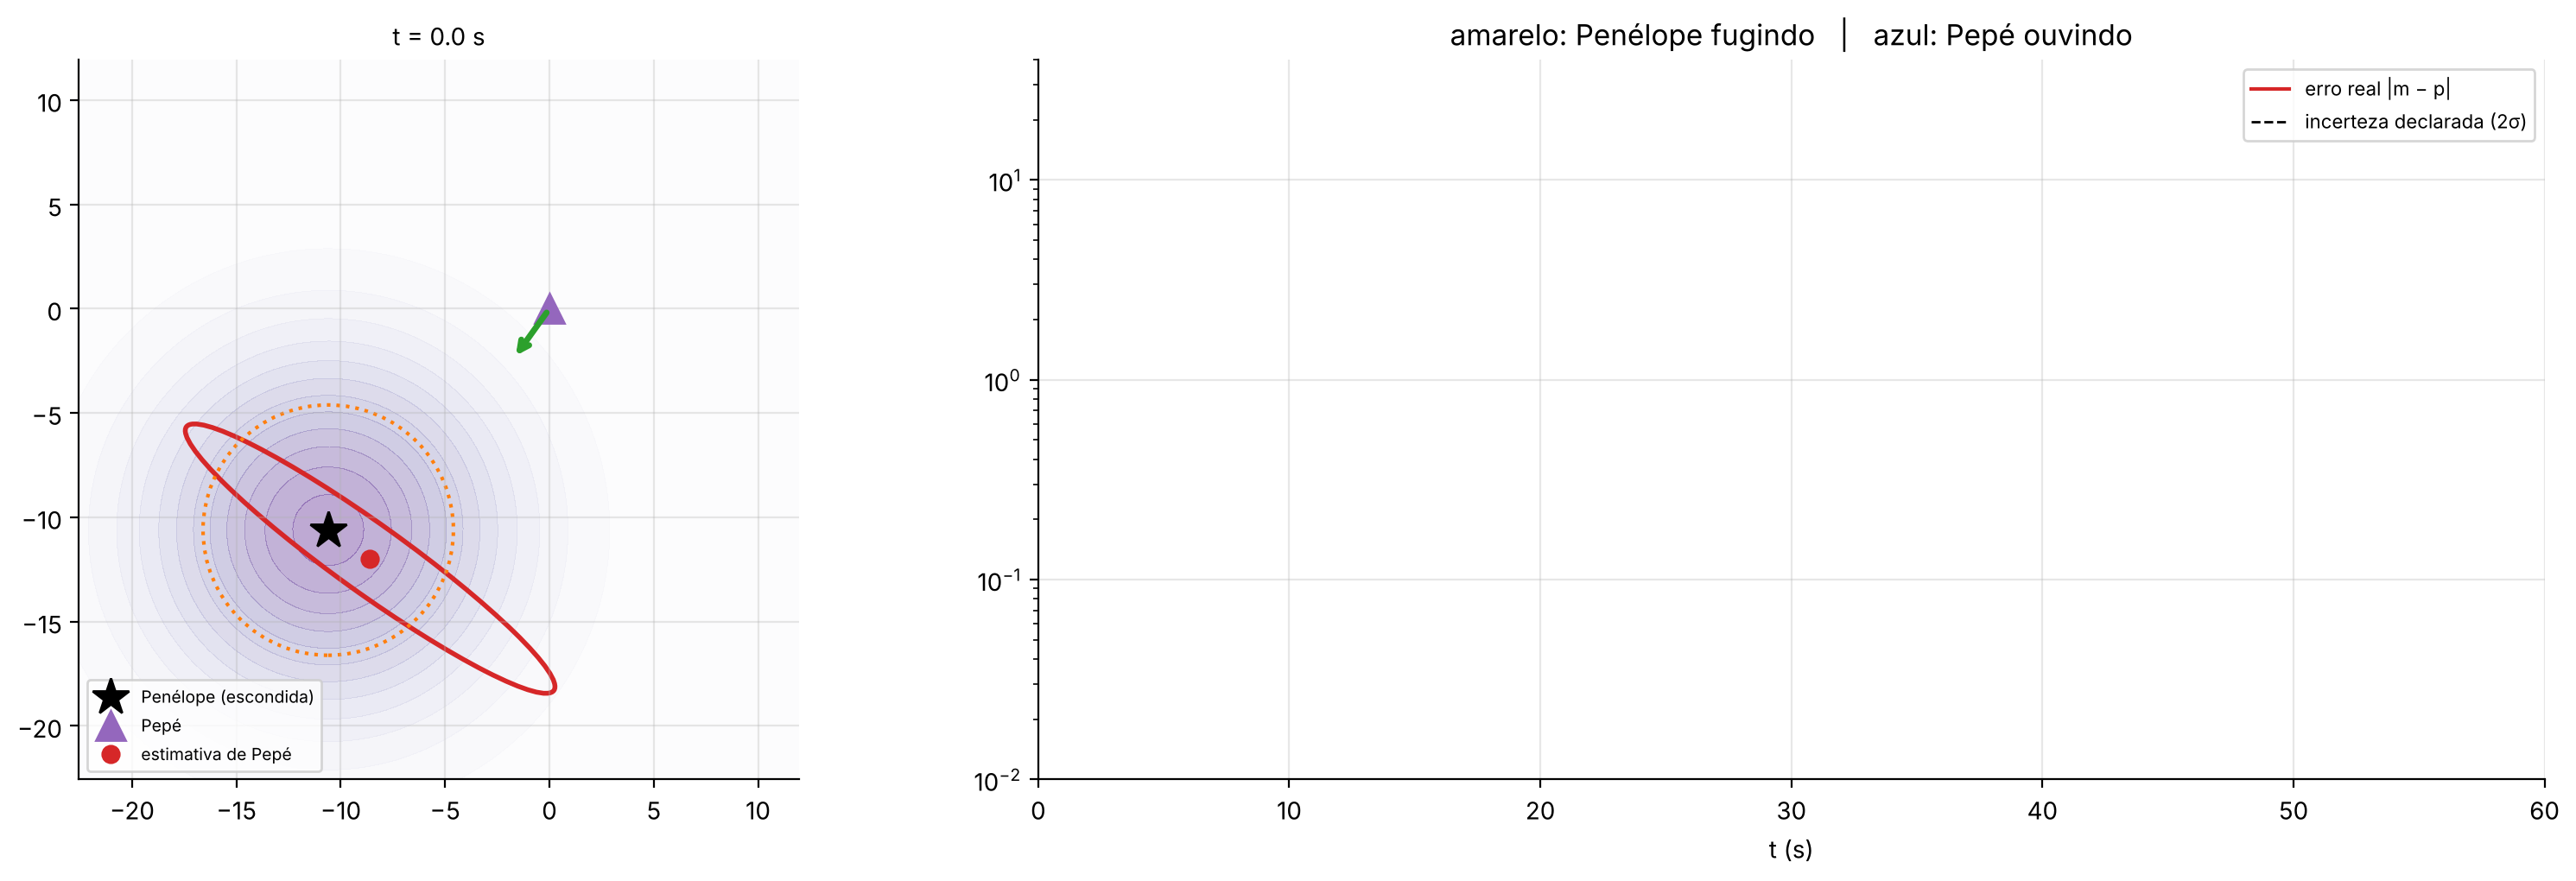

In [17]:
explica(reg3, 0)
quadro(reg3, 0)

### Quadro: o primeiro ciclo completo

Agora há **predição**: como a velocidade estimada é quase zero, $m^-$ fica praticamente onde estava, mas os desvios-padrão crescem um pouco ($Q$). Depois vem a correção. Veja no ganho $K$ que as linhas da **velocidade** já recebem parte da correção: Pepé começa a desconfiar de que ela se move.

══════════  passo k = 1  (t = 0.2 s)  ══════════
Pepé está em [-0.1166 -0.1625].  Penélope (oculta) está em [-10.6002 -10.613 ]
PREDIÇÃO   m⁻ = F m = [ -8.5927 -11.9797   0.       0.    ]
           desvios-padrão de m⁻ = [4.4344 3.2349 1.0954 1.0954]   (antes: [4.4296 3.2283 1.     1.    ])

MEDIDAS (nariz, 3 números):
        medida z  previsto h(m⁻)  inovação v  ruído σ    v/σ
∂c/∂x1    -0.024          -0.012      -0.011     0.01 -1.132
∂c/∂x2    -0.013          -0.017       0.004     0.01  0.416
c          0.074           0.053       0.021     0.02  1.074

KALMAN ITERADO: 10 iteração(ões); posição a cada iteração:
   s_0 = [ -8.5927 -11.9797]
   s_1 = [-10.8273  -9.8212]
   s_2 = [ -8.9801 -11.1946]
   s_3 = [-10.2949 -10.0899]
   s_4 = [ -9.2315 -10.92  ]
   s_5 = [-10.0263 -10.2595]
   ...

GANHO K (linhas = estado, colunas = medidas):
     ∂c/∂x1   ∂c/∂x2       c
p1  100.819 -157.107  38.426
p2 -102.853  108.465  -9.151
v1   -3.579   -1.774   2.900
v2   -6.811   -0.024   3.574



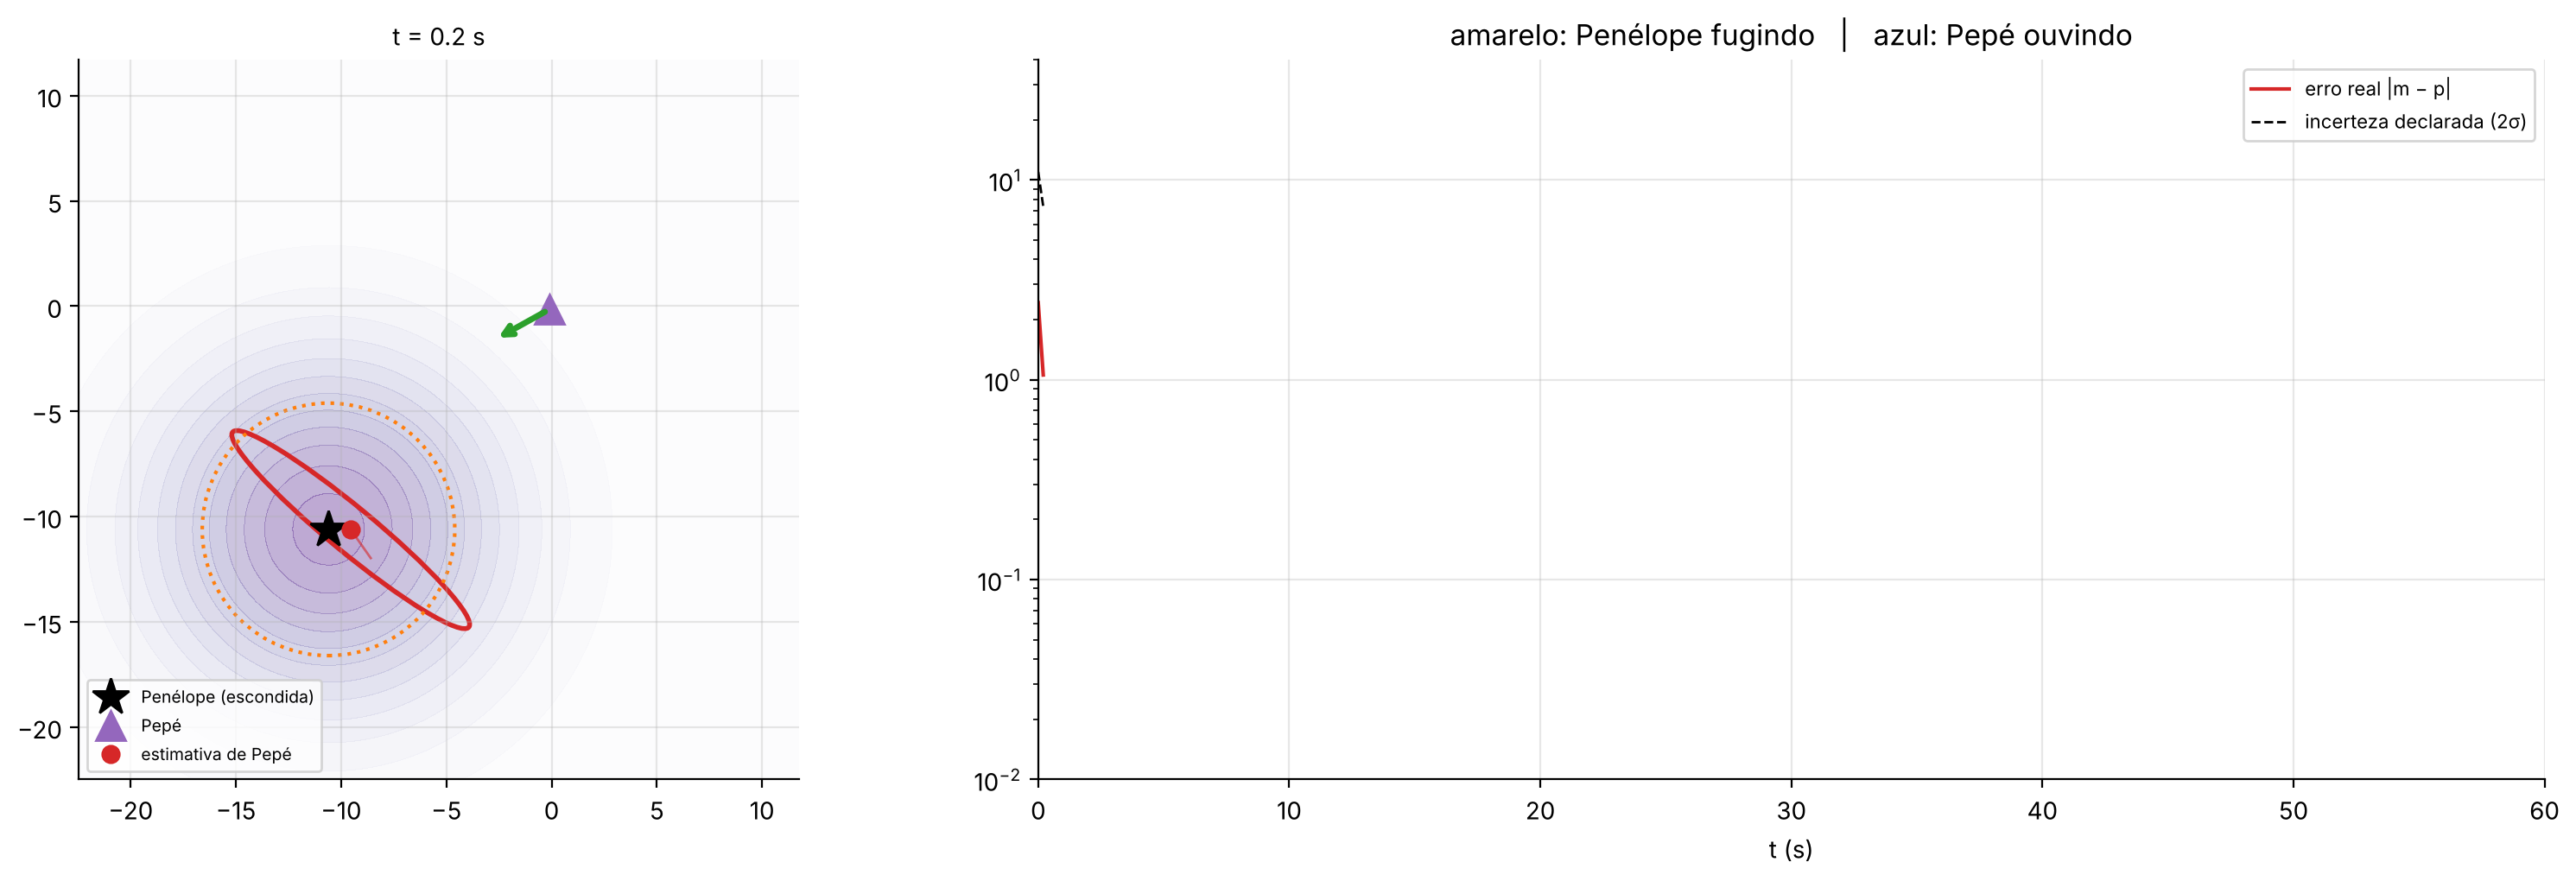

In [18]:
explica(reg3, 1)
quadro(reg3, 1)

### Quadro: dois segundos depois

A elipse ficou bem menor. Pepé ainda está longe demais para ouvir, então só usa o nariz (3 medidas). A velocidade estimada já não é zero: as linhas $v_1, v_2$ do ganho recebem correções a cada passo.

Repare que os números do ganho $K$ são grandes (dezenas). Isso não é um problema: $K$ converte **unidades de medida** em **unidades de estado**, e as medidas do cheiro são números pequenos (centésimos). Uma inovação de 0,01 no gradiente multiplicada por 40 move a estimativa em 0,4 unidade de posição.

══════════  passo k = 10  (t = 2.0 s)  ══════════
Pepé está em [-1.4228 -1.3975].  Penélope (oculta) está em [-10.6002 -10.613 ]
PREDIÇÃO   m⁻ = F m = [-10.486  -10.5508   0.4299  -0.176 ]
           desvios-padrão de m⁻ = [1.3812 1.5151 1.289  1.2872]   (antes: [1.2495 1.3806 1.2089 1.207 ])

MEDIDAS (nariz, 3 números):
        medida z  previsto h(m⁻)  inovação v  ruído σ    v/σ
∂c/∂x1    -0.034          -0.025      -0.009     0.01 -0.899
∂c/∂x2    -0.033          -0.025      -0.007     0.01 -0.714
c          0.117           0.100       0.017     0.02  0.842

KALMAN ITERADO: 10 iteração(ões); posição a cada iteração:
   s_0 = [-10.486  -10.5508]
   s_1 = [-10.4911 -10.0931]
   s_2 = [-10.4069 -10.1758]
   s_3 = [-10.4357 -10.1448]
   s_4 = [-10.4253 -10.1557]
   s_5 = [-10.429  -10.1518]
   ...

GANHO K (linhas = estado, colunas = medidas):
    ∂c/∂x1  ∂c/∂x2       c
p1  38.742 -46.736   4.458
p2 -53.171  38.055  10.766
v1  12.181 -29.297  10.853
v2 -27.708  13.333   9.815

CORREÇÃO 

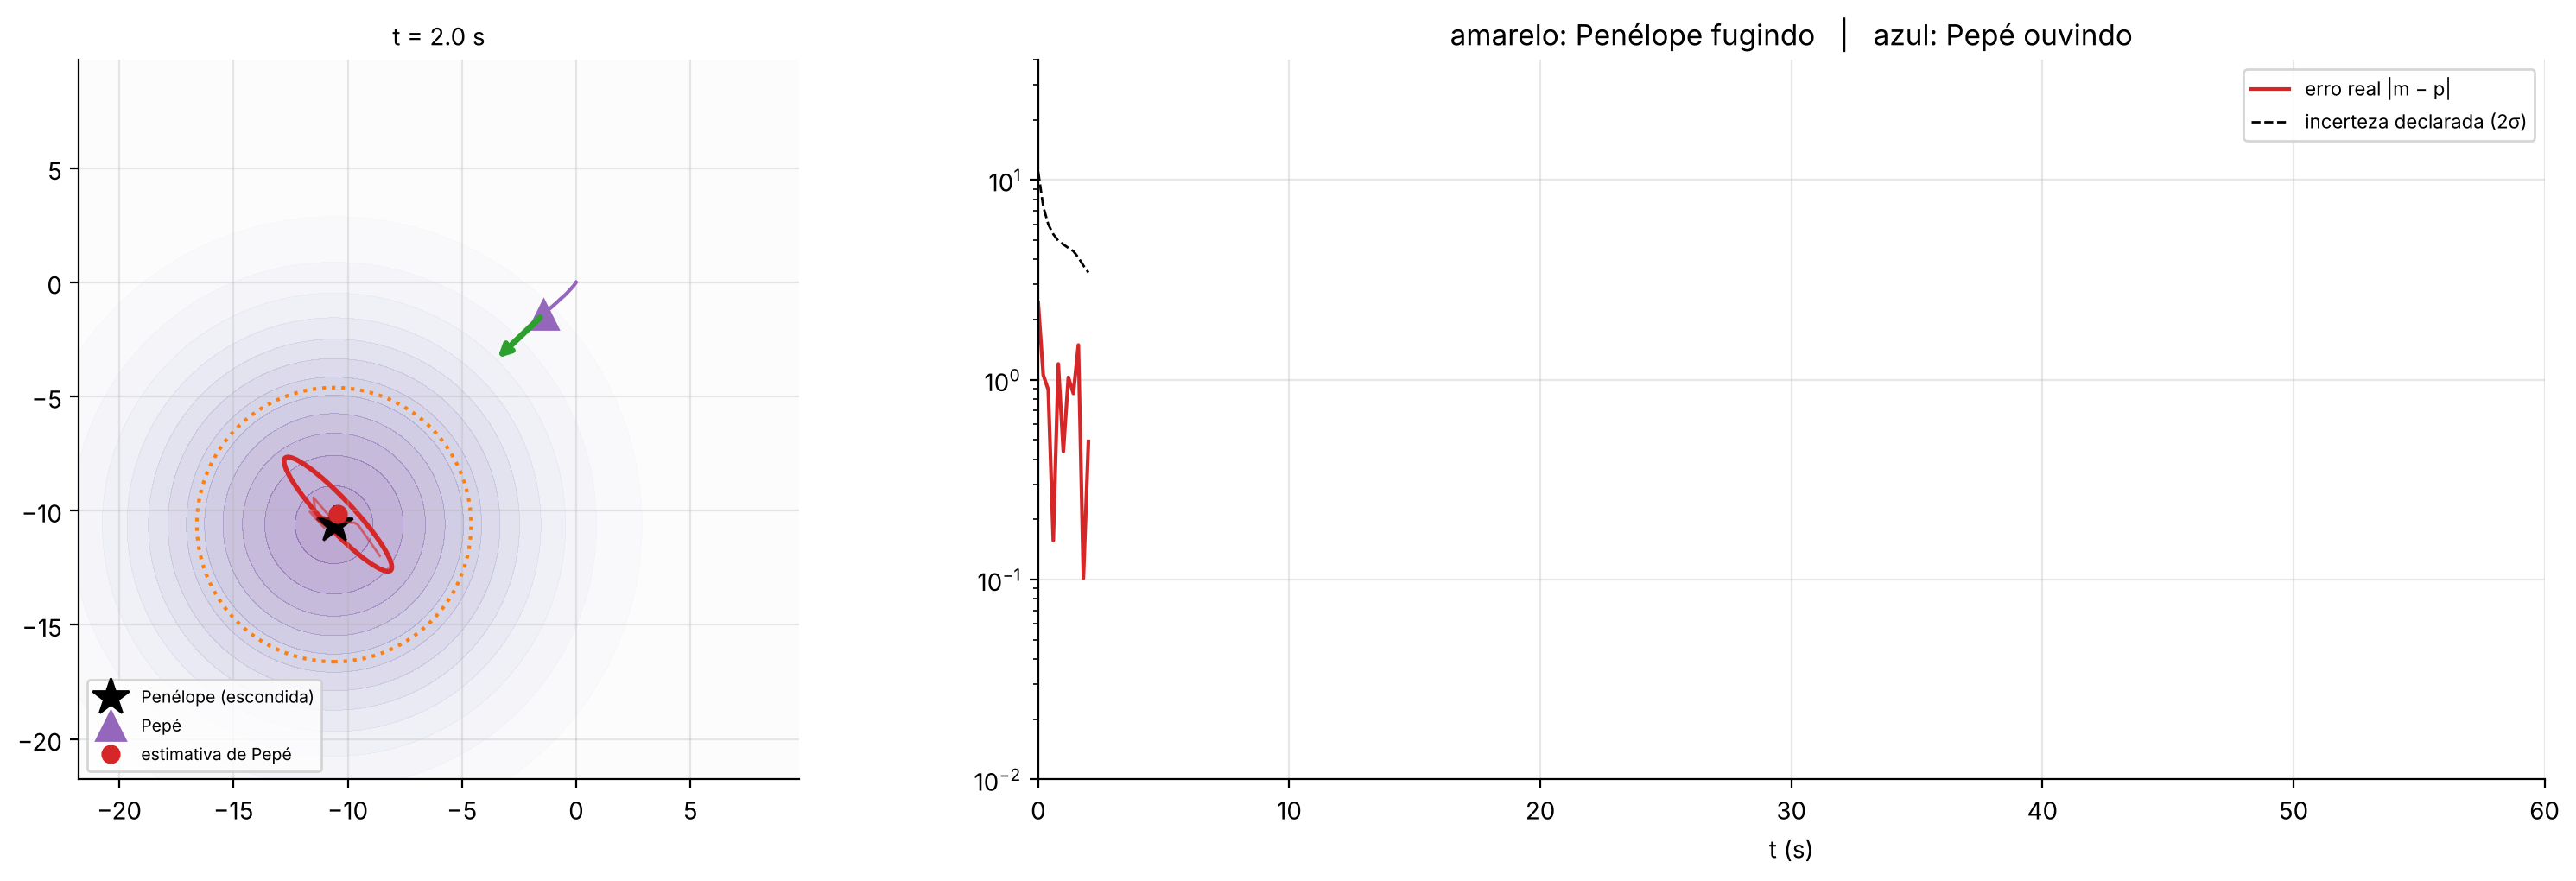

In [19]:
explica(reg3, 10)
quadro(reg3, 10)

### Quadro: Pepé começa a ouvir

O vetor de medidas passa de 3 para 6 números, e o ganho $K$ ganha 3 colunas. Os ruídos do som são pequenos, então as colunas do som recebem pesos grandes, e a elipse encolhe de forma visível.

══════════  passo k = 46  (t = 9.2 s)  ══════════
Pepé está em [-6.4045 -6.5712].  Penélope (oculta) está em [-10.6002 -10.613 ]  — Pepé OUVE o coração
PREDIÇÃO   m⁻ = F m = [-10.8287 -10.6475  -0.2633   0.1373]
           desvios-padrão de m⁻ = [0.405  0.4209 0.8354 0.8424]   (antes: [0.3001 0.3133 0.7056 0.7139])

MEDIDAS (nariz + ouvidos, 6 números):
        medida z  previsto h(m⁻)  inovação v  ruído σ    v/σ
∂c/∂x1    -0.062          -0.074       0.013    0.010  1.259
∂c/∂x2    -0.076          -0.068      -0.007    0.010 -0.700
c          0.623           0.605       0.018    0.020  0.909
∂s/∂x1    -0.008          -0.006      -0.002    0.002 -1.031
∂s/∂x2    -0.008          -0.006      -0.002    0.002 -0.990
s          0.025           0.027      -0.002    0.003 -0.701

KALMAN ITERADO: 8 iteração(ões); posição a cada iteração:
   s_0 = [-10.8287 -10.6475]
   s_1 = [-10.5251 -10.8253]
   s_2 = [-10.5319 -10.8075]
   s_3 = [-10.5313 -10.8081]
   s_4 = [-10.5313 -10.8081]
   s_5 = [-10

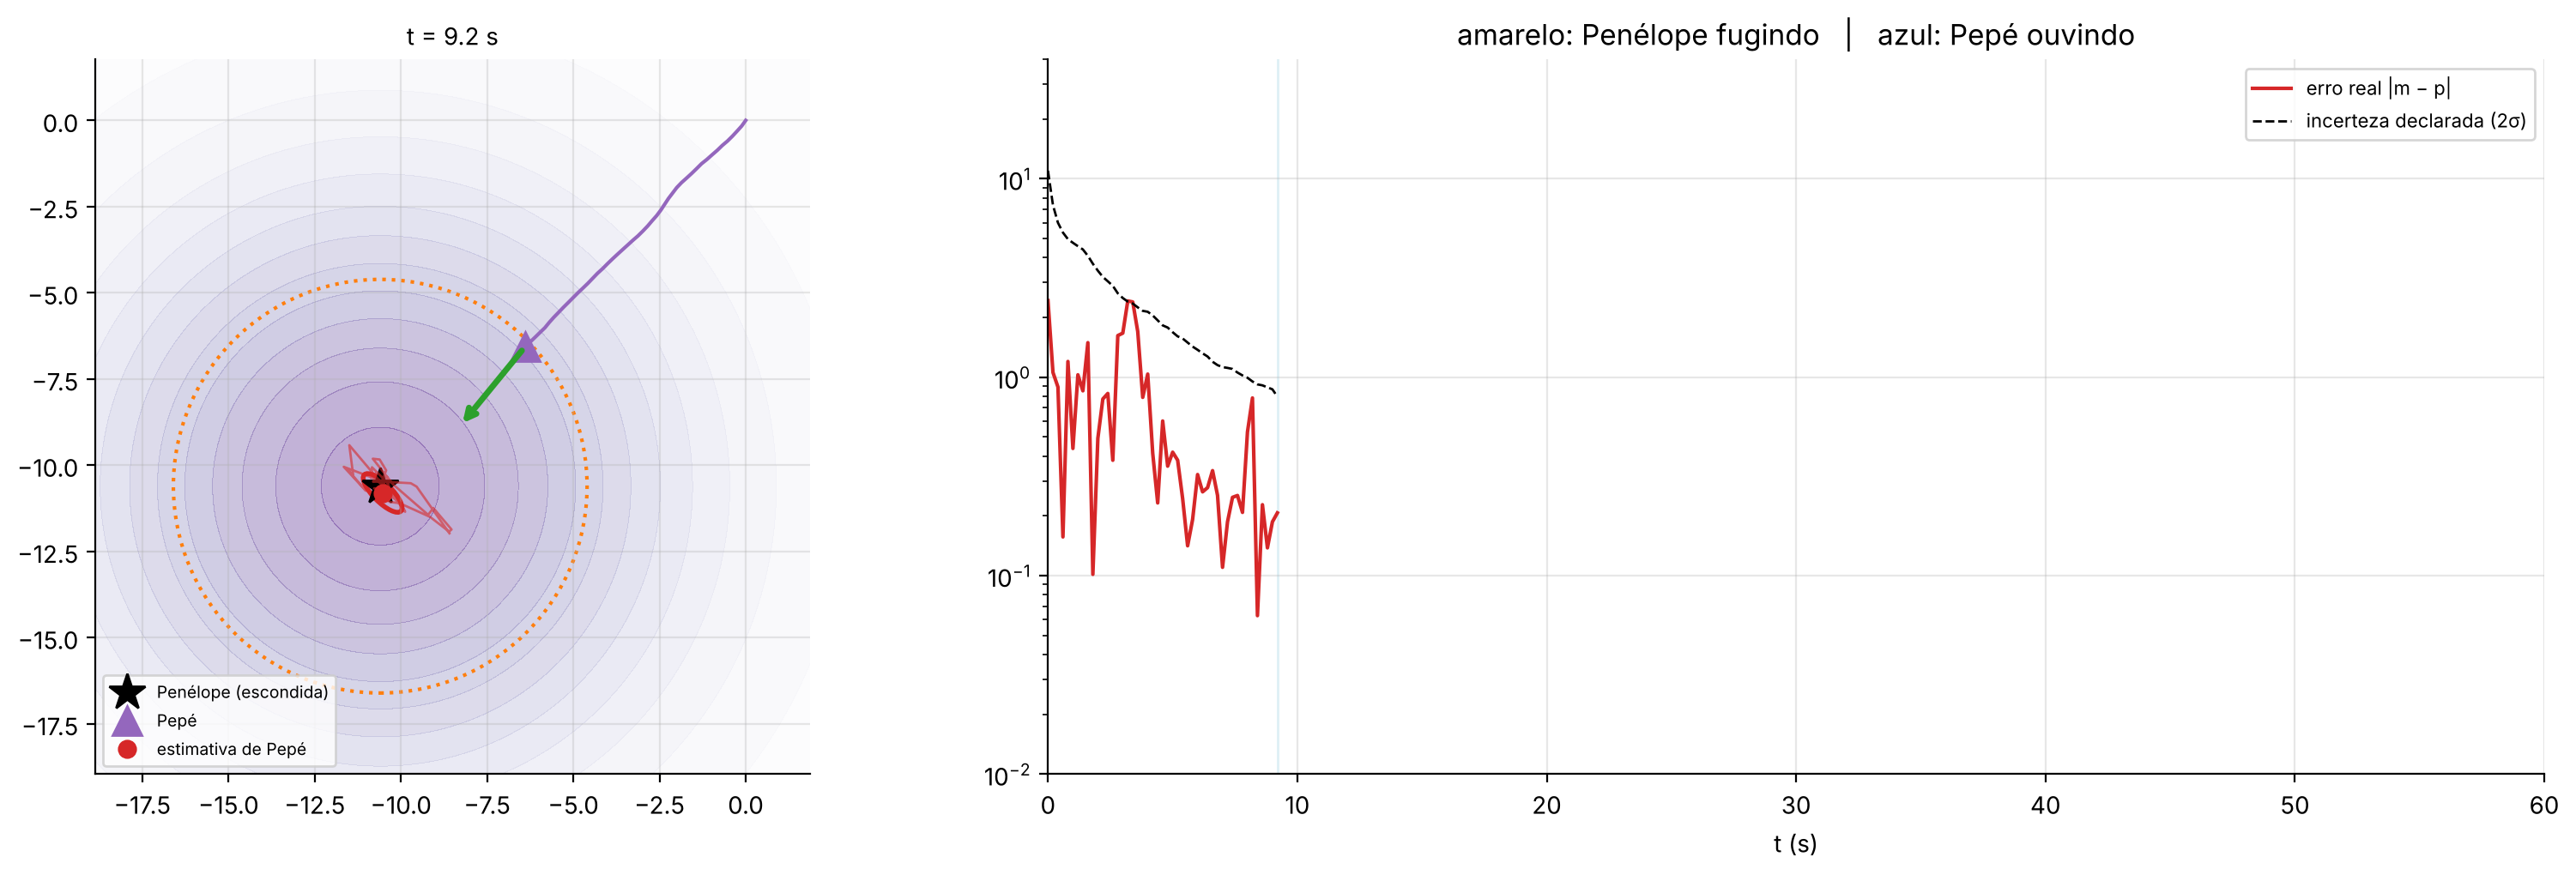

In [20]:
explica(reg3, k_ouve)
quadro(reg3, k_ouve)

### Quadro: um instante antes da primeira fuga

Pepé já está ouvindo e chegando perto. A estimativa está muito boa e a incerteza, pequena. Penélope, parada, está prestes a sentir o cheiro dele.

══════════  passo k = 53  (t = 10.6 s)  ══════════
Pepé está em [-7.3682 -7.5865].  Penélope (oculta) está em [-10.6002 -10.613 ]  — Pepé OUVE o coração
PREDIÇÃO   m⁻ = F m = [-10.3836 -10.7644   0.2682   0.209 ]
           desvios-padrão de m⁻ = [0.2934 0.2855 0.7592 0.7494]   (antes: [0.2008 0.195  0.6135 0.6013])

MEDIDAS (nariz + ouvidos, 6 números):
        medida z  previsto h(m⁻)  inovação v  ruído σ    v/σ
∂c/∂x1    -0.062          -0.064   2.085e-03    0.010  0.209
∂c/∂x2    -0.067          -0.068   5.733e-04    0.010  0.057
c          0.759           0.766  -7.416e-03    0.020 -0.371
∂s/∂x1    -0.015          -0.015  -3.882e-04    0.002 -0.194
∂s/∂x2    -0.012          -0.016   3.686e-03    0.002  1.843
s          0.051           0.050   1.048e-03    0.003  0.349

KALMAN ITERADO: 9 iteração(ões); posição a cada iteração:
   s_0 = [-10.3836 -10.7644]
   s_1 = [-10.5469 -10.6746]
   s_2 = [-10.5476 -10.666 ]
   s_3 = [-10.5482 -10.6653]
   s_4 = [-10.5482 -10.6652]
   s_5 = [-1

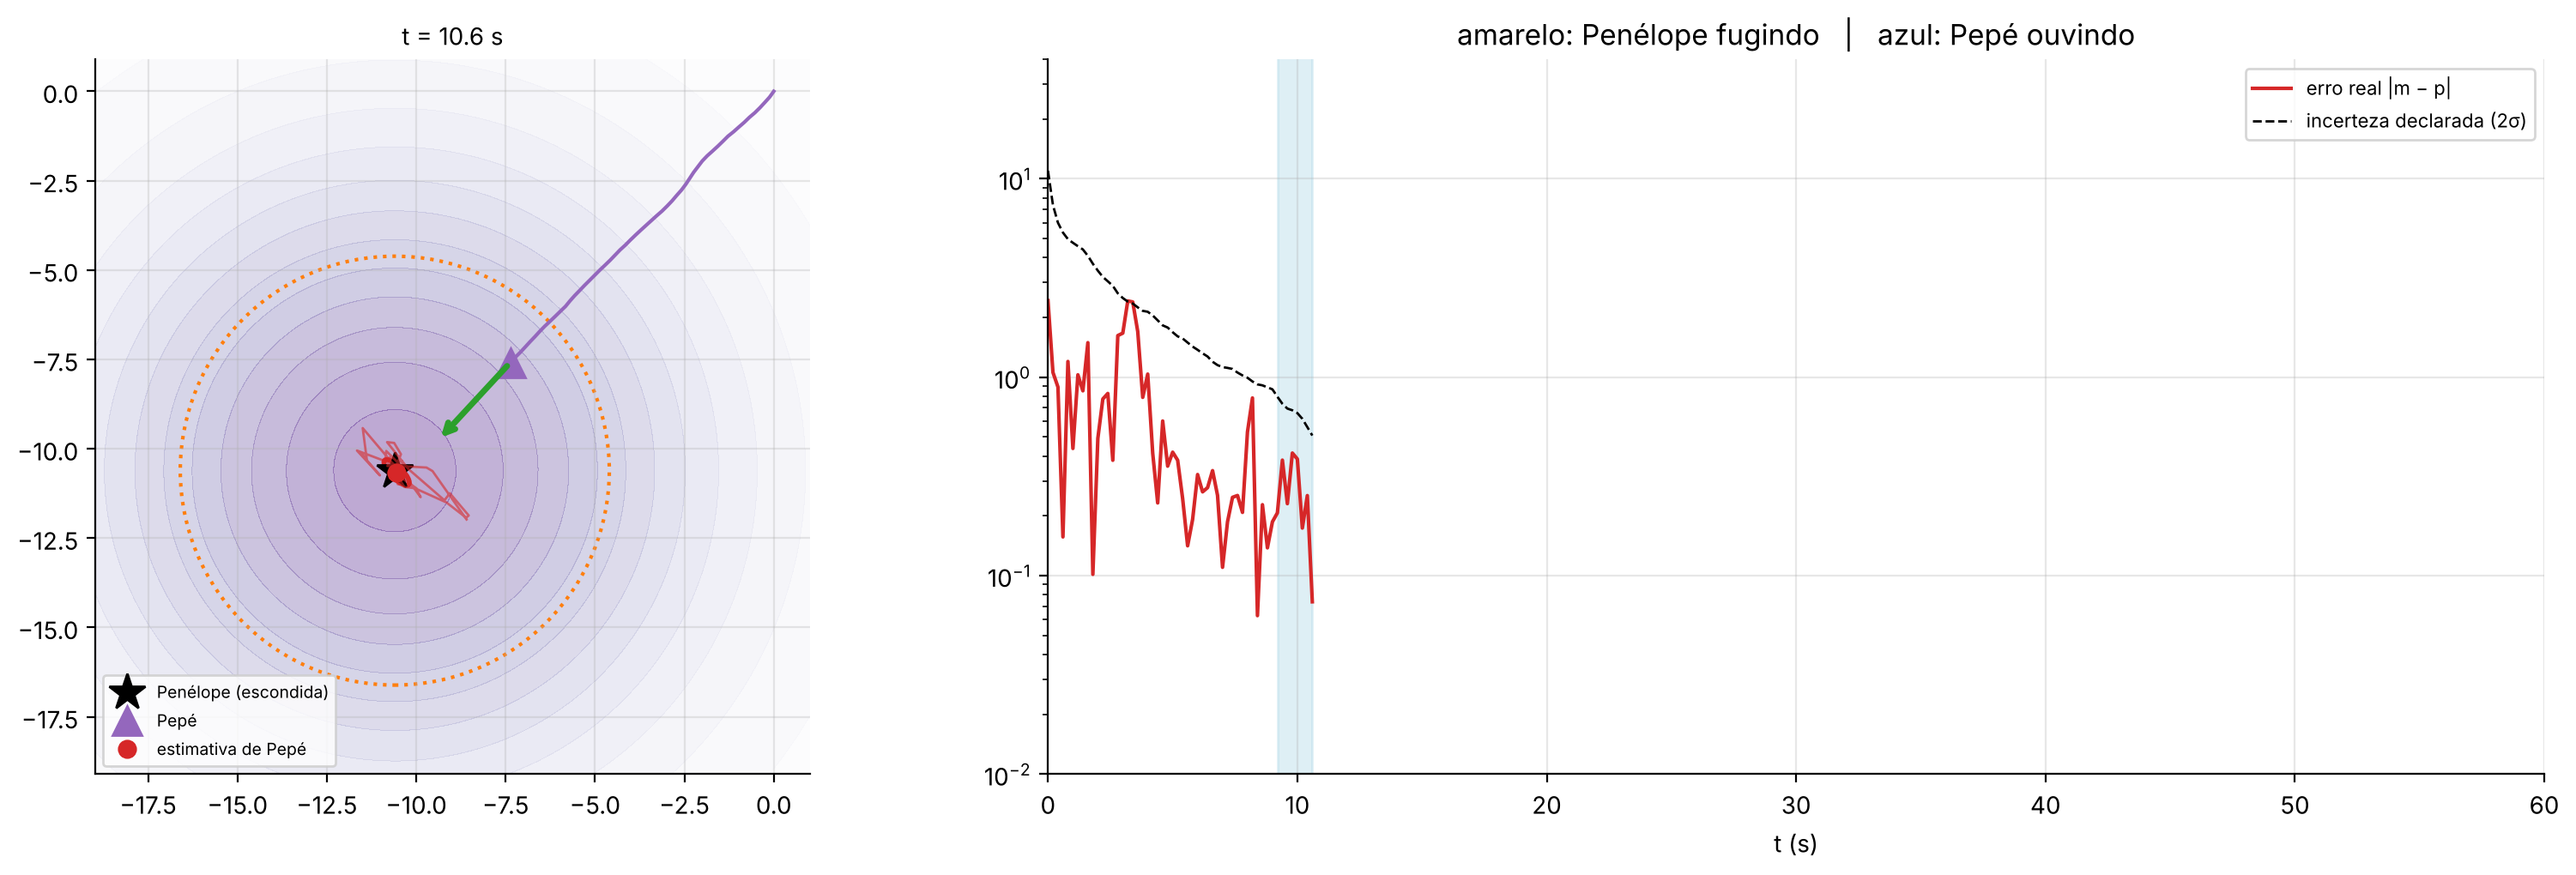

In [21]:
explica(reg3, k_fuga - 1)
quadro(reg3, k_fuga - 1)

### Quadro: Penélope está fugindo

Ela acelerou de repente, e o modelo de Pepé (velocidade quase constante) não previa isso. As **inovações** ficam grandes: a medida "puxa" a estimativa, e o ganho $K$ transfere parte da surpresa para a **velocidade**. No painel da direita, o erro real sobe e pode passar da faixa declarada: é o filtro sendo surpreendido por um modelo simples demais. A Parte 2 trata disso.

══════════  passo k = 56  (t = 11.2 s)  ══════════
Pepé está em [-7.8039 -7.9989].  Penélope (oculta) está em [-11.2124 -11.5366]  — FUGINDO  — Pepé OUVE o coração
PREDIÇÃO   m⁻ = F m = [-11.1993 -11.1013  -1.0088  -0.6405]
           desvios-padrão de m⁻ = [0.2679 0.2799 0.735  0.7449]   (antes: [0.1758 0.1854 0.5833 0.5957])

MEDIDAS (nariz + ouvidos, 6 números):
        medida z  previsto h(m⁻)  inovação v  ruído σ    v/σ
∂c/∂x1    -0.059          -0.070   1.133e-02    0.010  1.133
∂c/∂x2    -0.051          -0.064   1.275e-02    0.010  1.275
c          0.745           0.745  -5.325e-04    0.020 -0.027
∂s/∂x1    -0.013          -0.014   7.547e-04    0.002  0.377
∂s/∂x2    -0.015          -0.013  -1.935e-03    0.002 -0.968
s          0.042           0.045  -2.901e-03    0.003 -0.967

KALMAN ITERADO: 8 iteração(ões); posição a cada iteração:
   s_0 = [-11.1993 -11.1013]
   s_1 = [-11.1487 -11.1855]
   s_2 = [-11.1454 -11.1866]
   s_3 = [-11.1452 -11.1867]
   s_4 = [-11.1452 -11.1867]
 

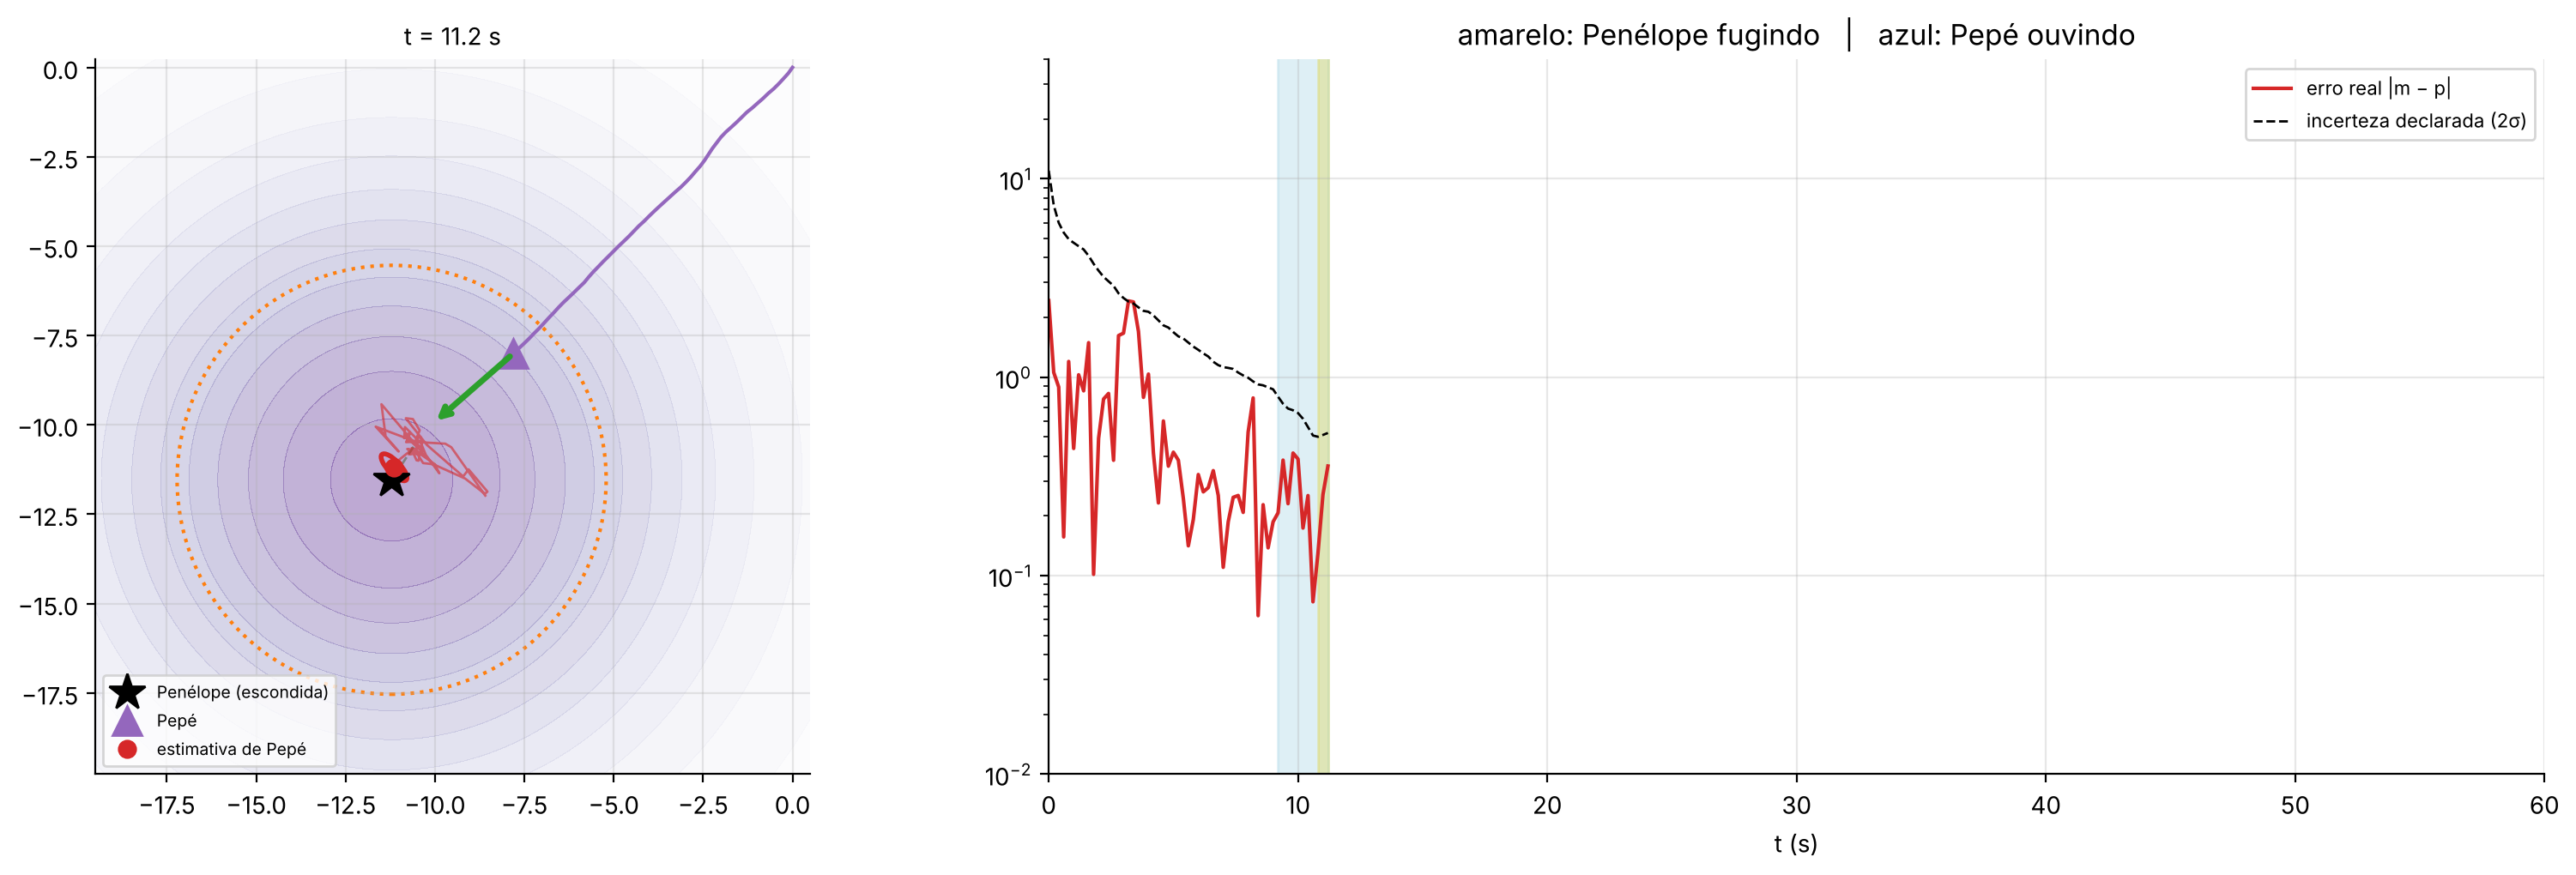

In [22]:
explica(reg3, k_fuga + 2)
quadro(reg3, k_fuga + 2)

### Quadro: a fuga acabou

Penélope parou, mas Pepé ainda acha que ela se move (a velocidade estimada não zerou de imediato). As próximas medidas vão freando a estimativa de velocidade, porque a posição "aparente" parou de mudar.

══════════  passo k = 71  (t = 14.2 s)  ══════════
Pepé está em [ -9.7598 -10.2694].  Penélope (oculta) está em [-13.457  -14.9232]  — Pepé OUVE o coração
PREDIÇÃO   m⁻ = F m = [-13.3351 -15.3091   0.143   -0.6009]
           desvios-padrão de m⁻ = [0.448  0.3769 0.8616 0.8077]   (antes: [0.3365 0.2774 0.7364 0.6725])

MEDIDAS (nariz + ouvidos, 6 números):
        medida z  previsto h(m⁻)  inovação v  ruído σ    v/σ
∂c/∂x1    -0.063          -0.058      -0.005    0.010 -0.451
∂c/∂x2    -0.092          -0.082      -0.010    0.010 -1.001
c          0.647           0.588       0.058    0.020  2.912
∂s/∂x1    -0.003          -0.005       0.002    0.002  0.988
∂s/∂x2    -0.008          -0.007      -0.001    0.002 -0.707
s          0.030           0.026       0.004    0.003  1.440

KALMAN ITERADO: 10 iteração(ões); posição a cada iteração:
   s_0 = [-13.3351 -15.3091]
   s_1 = [-13.0075 -15.1048]
   s_2 = [-13.017  -15.1108]
   s_3 = [-13.0171 -15.1106]
   s_4 = [-13.017  -15.1106]
   s_5 = 

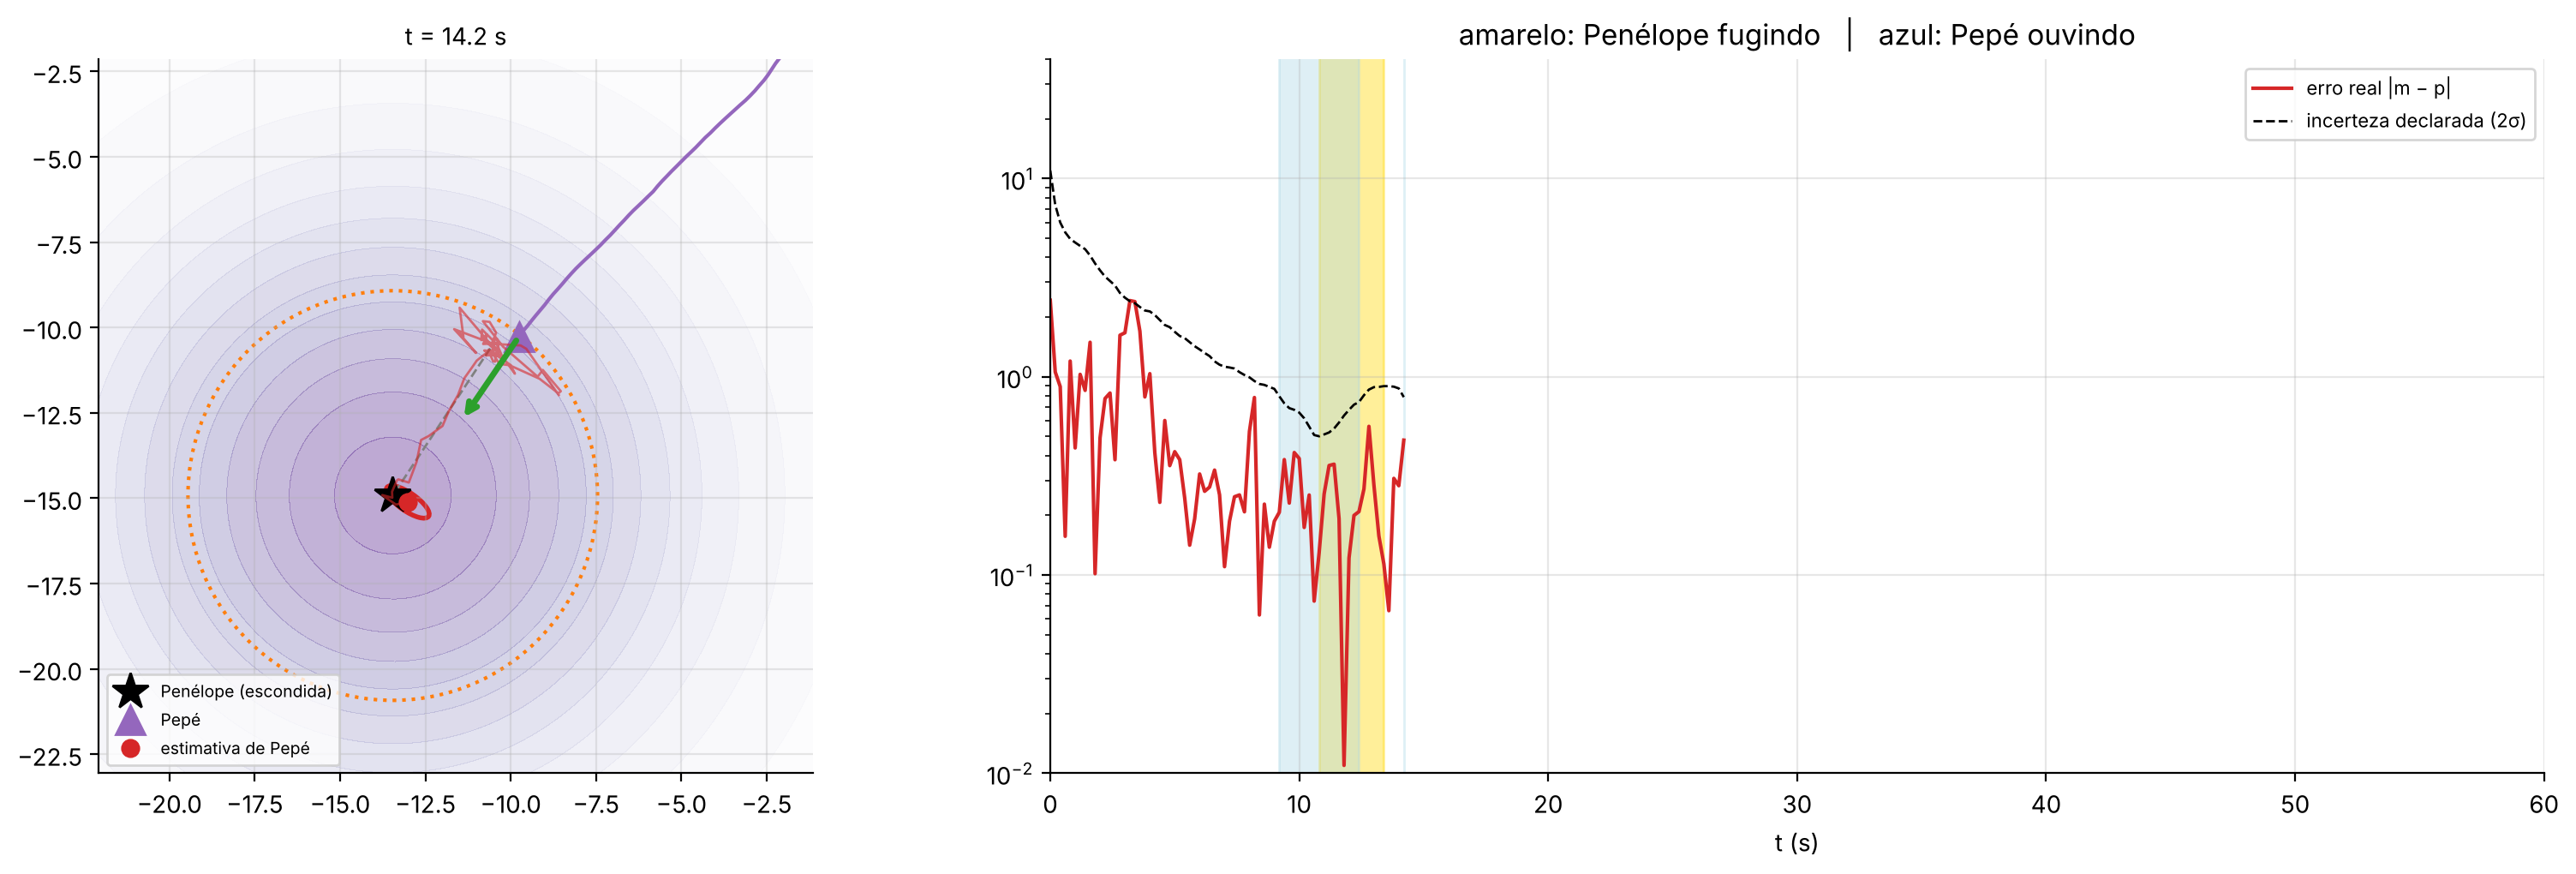

In [23]:
explica(reg3, k_fim_fuga + 3)
quadro(reg3, k_fim_fuga + 3)

### Quadro: o fim

Sessenta segundos, trezentas medidas, uma de cada vez. No painel da direita, compare o erro real com a incerteza declarada. Quando a curva vermelha fica abaixo da tracejada, Pepé está sendo honesto sobre o que sabe. Os momentos em que ela passa por cima concentram-se nas fugas.

══════════  passo k = 299  (t = 59.8 s)  ══════════
Pepé está em [ 15.5099 -20.4171].  Penélope (oculta) está em [ 20.0785 -16.916 ]  — Pepé OUVE o coração
PREDIÇÃO   m⁻ = F m = [ 21.2529 -17.5264   2.0373  -0.1856]
           desvios-padrão de m⁻ = [0.3149 0.4481 0.7628 0.8575]   (antes: [0.2237 0.3323 0.618  0.7316])

MEDIDAS (nariz + ouvidos, 6 números):
        medida z  previsto h(m⁻)  inovação v  ruído σ    v/σ
∂c/∂x1     0.071           0.090      -0.018    0.010 -1.836
∂c/∂x2     0.064           0.045       0.019    0.010  1.926
c          0.613           0.563       0.050    0.020  2.489
∂s/∂x1     0.008           0.006       0.002    0.002  0.844
∂s/∂x2     0.007           0.003       0.004    0.002  1.804
s          0.027           0.024       0.003    0.003  1.146

KALMAN ITERADO: 10 iteração(ões); posição a cada iteração:
   s_0 = [ 21.2529 -17.5264]
   s_1 = [ 20.6236 -17.0391]
   s_2 = [ 20.6343 -17.1368]
   s_3 = [ 20.6248 -17.1227]
   s_4 = [ 20.6258 -17.1249]
   s_5 =

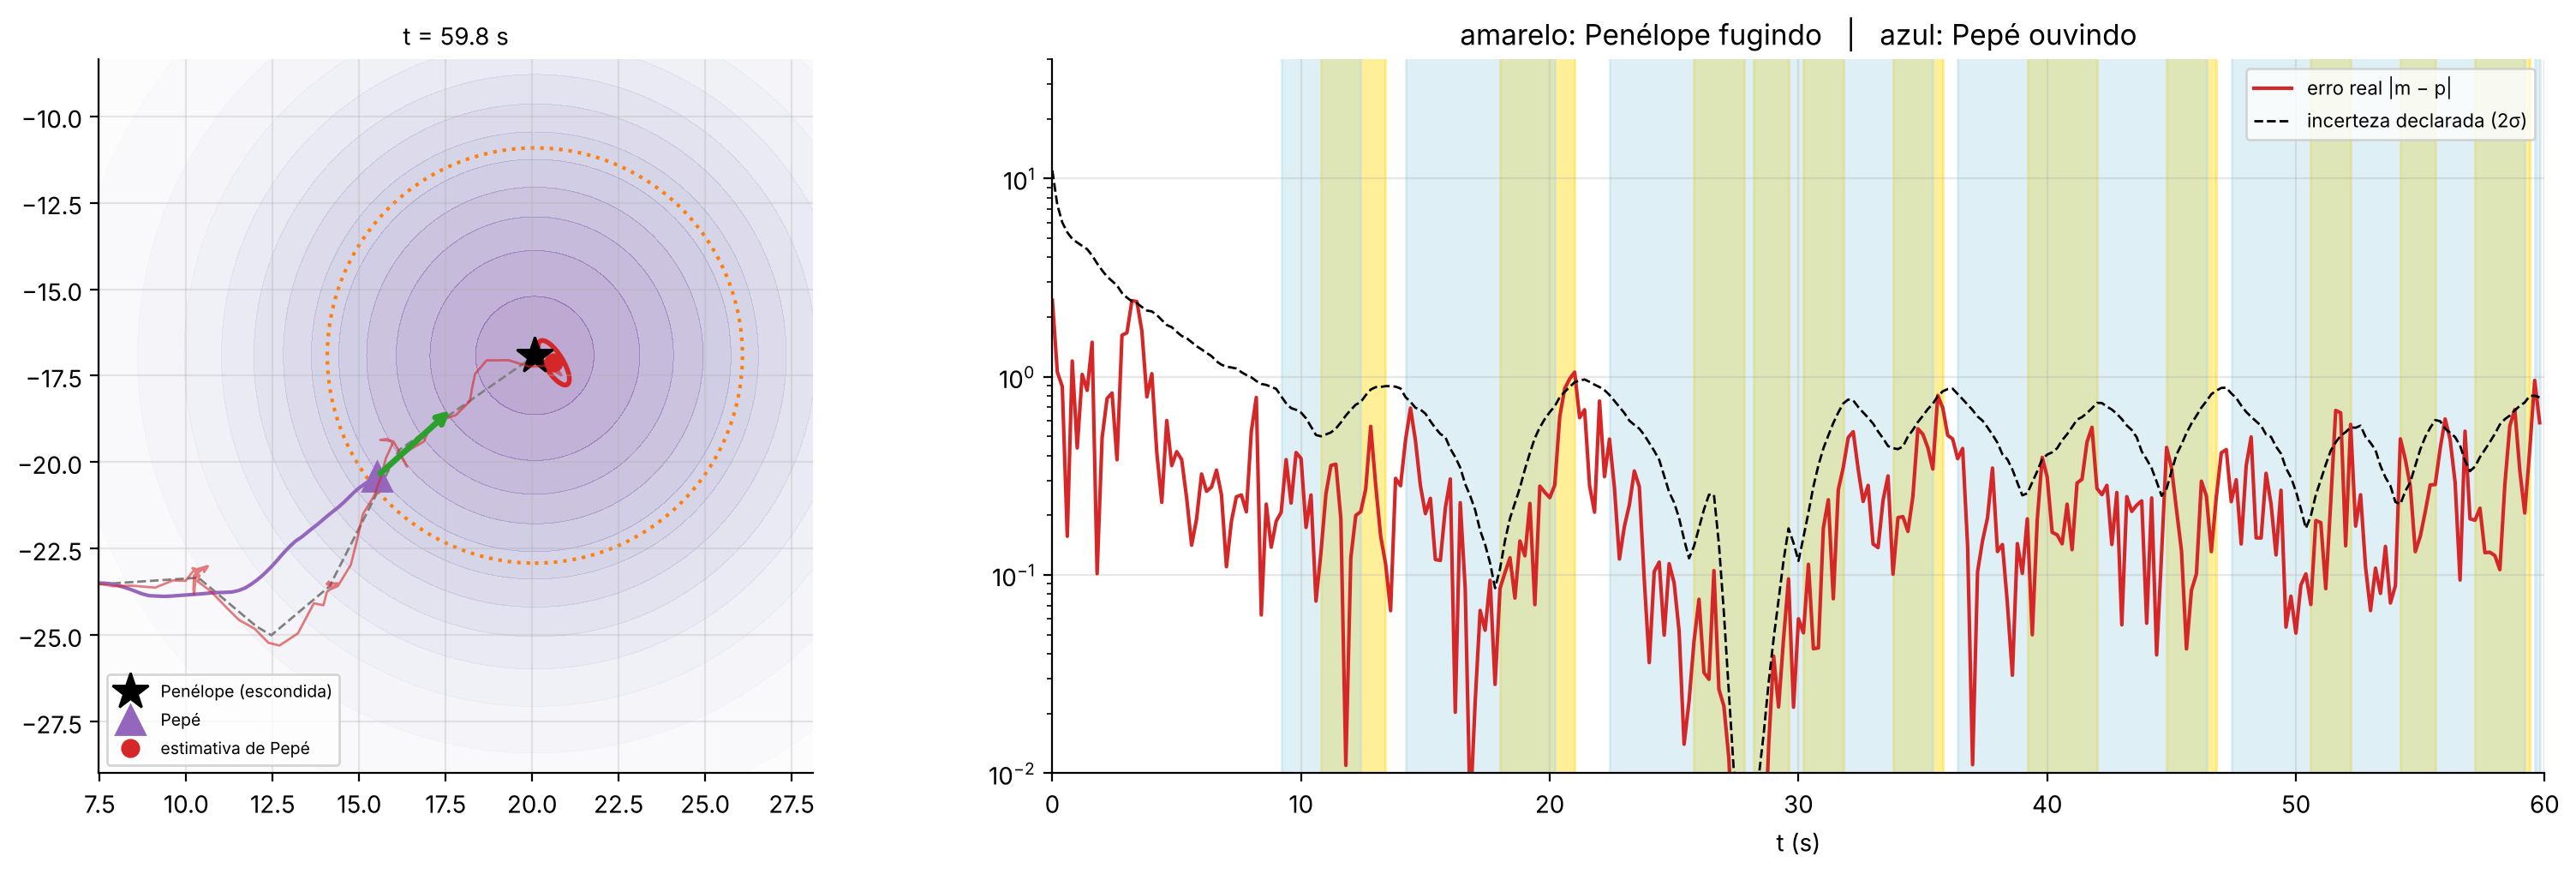

In [24]:
explica(reg3, N_PASSOS - 1)
quadro(reg3, N_PASSOS - 1)

---
# 9. Comparação estatística e o Pepé teimoso

Uma perseguição só pode enganar. Rodamos **40 perseguições** (sementes diferentes) para cada combinação e medimos:

- **erro mediano** da estimativa de posição ao longo da perseguição;
- **fração do tempo "perdido"**: erro maior que 10 unidades;
- **consistência**: fração do tempo em que Penélope está **dentro** da elipse de 2σ de Pepé. Num filtro honesto, isso fica perto de 86% (a probabilidade da elipse de 2σ de uma gaussiana 2D, $1-e^{-2}$).

E entra o **Pepé teimoso**, o do desenho: Kalman iterado com $q=10^{-6}$. Ele acredita que Penélope praticamente não muda de velocidade, ou seja, que **ela não foge**.

In [25]:
configs = {
    "F1 ingênuo (filtro EKF de carona)":   dict(estrategia="ingenuo", fase=1, n_iter=1),
    "F1 EKF":                              dict(fase=1, n_iter=1),
    "F1 Kalman iterado":                   dict(fase=1, n_iter=10),
    "F2 EKF":                              dict(fase=2, n_iter=1),
    "F2 Kalman iterado":                   dict(fase=2, n_iter=10),
    "F3 Kalman iterado":                   dict(fase=3, n_iter=10),
    "F3 Kalman iterado, Pepé TEIMOSO":     dict(fase=3, n_iter=10, q=1e-6),
}
linhas = []
for nome, kw in configs.items():
    E, PERD, CONS = [], [], []
    for sd in range(40):
        S_ = series(simula(seed=100 + sd, **kw))
        E.append(np.median(S_["erro"])); PERD.append(np.mean(S_["erro"] > 10)); CONS.append(np.mean(S_["nees"] <= 4.0))
    linhas.append(dict(configuração=nome, **{"erro mediano": np.median(E), "tempo perdido (%)": 100 * np.mean(PERD),
                                              "dentro da elipse 2σ (%)": 100 * np.mean(CONS)}))
tabela = pd.DataFrame(linhas).set_index("configuração")
tabela

,erro mediano,tempo perdido (%),dentro da elipse 2σ (%)
configuração,,,
F1 ingênuo (filtro EKF de carona),4.737,30.292,32.308
F1 EKF,2.827,25.000,35.208
F1 Kalman iterado,1.358,13.483,44.958
F2 EKF,520.765,98.817,0.000
F2 Kalman iterado,0.317,0.533,84.458
F3 Kalman iterado,0.189,0.533,84.575
"F3 Kalman iterado, Pepé TEIMOSO",21.378,58.492,13.058


**Como ler a tabela.**

- **Da Fase 1 para a Fase 3, com o Kalman iterado**, o erro cai de forma marcante, e o tempo "perdido" praticamente desaparece. Cada sensor novo traz informação sobre um aspecto diferente da posição.
- **O EKF da Fase 2 é pior que o da Fase 1.** Não é a intensidade que atrapalha; é linearizar a intensidade num ponto ruim. O Kalman iterado transforma a mesma medida em ganho.
- **Consistência.** Nas Fases 2 e 3, Penélope está dentro da elipse de 2σ cerca de 85% do tempo, perto dos 86% ideais: o Kalman iterado é **honesto** sobre o que sabe. O pequeno déficit vem das fugas, que o modelo de Pepé (velocidade quase constante) não descreve; durante elas o filtro fica um pouco confiante demais. Na Fase 1 a consistência cai para menos de 50%: só com o gradiente, a linearização engana sobre a distância e o filtro declara certeza que não tem. É o problema que a intensidade resolve, e que o IMM da Parte 2 ataca do lado do modelo de movimento.
- **O Pepé teimoso** tem bons sensores, mas um *prior* rígido sobre o movimento: ele acompanha Penélope enquanto ela está parada e se perde a cada fuga. Como no desenho, **o problema não é a falta de evidência, é a recusa em atualizar a crença**. E repare no painel da direita da figura abaixo: como Pepé anda para onde **acha** que Penélope está, a crença errada o leva embora junto com ela.

Para ver a teimosia acontecendo, uma mesma perseguição com os dois Pepés:

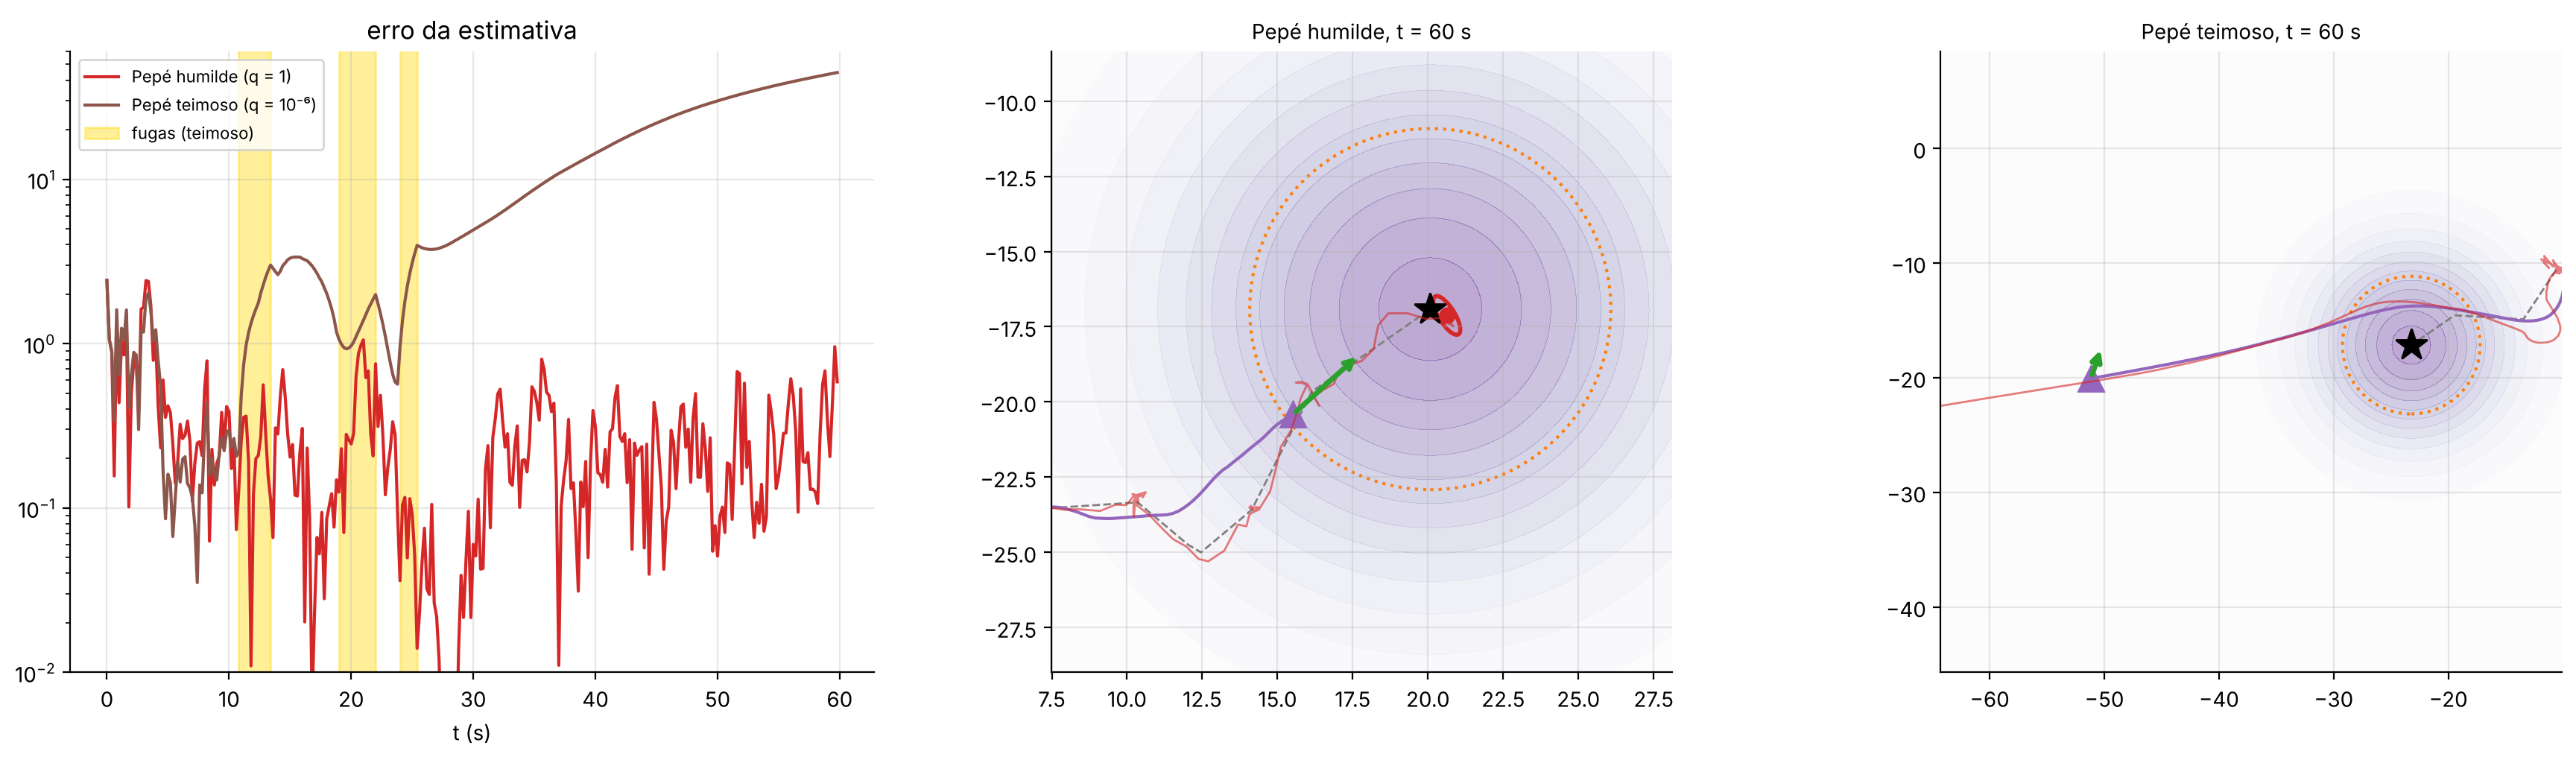

In [26]:
reg_t = simula("kalman", 3, SEED, n_iter=10, q=1e-6)
fig, ax = plt.subplots(1, 3, figsize=(18, 5.2))
S_a, S_b = series(reg3), series(reg_t)
for S_, nome, cor in [(S_a, "Pepé humilde (q = 1)", "C3"), (S_b, "Pepé teimoso (q = 10⁻⁶)", "C5")]:
    ax[0].plot(S_["t"], S_["erro"], color=cor, label=nome)
ax[0].fill_between(S_b["t"], 1e-2, 1e2, where=S_b["fugindo"], color="gold", alpha=.4, step="mid", label="fugas (teimoso)")
ax[0].set_yscale("log"); ax[0].set_ylim(1e-2, 60); ax[0].legend(fontsize=8); ax[0].set_title("erro da estimativa"); ax[0].set_xlabel("t (s)")
desenha_arena(ax[1], reg3, 299, "Pepé humilde, t = 60 s", mostra_som=True)
desenha_arena(ax[2], reg_t, 299, "Pepé teimoso, t = 60 s", mostra_som=True)
plt.tight_layout(); plt.show()

---
# 10. Kalman como aprendizado de máquina: resumo

| ideia do filtro | leitura em aprendizado de máquina |
|---|---|
| estado $s$ (posição e velocidade de Penélope) | parâmetro desconhecido que se aprende **online** |
| *prior* $(m_0,P_0)$ e predição | **regularização**: não se afastar do que já se sabia |
| medidas $z$ e modelo $h$ | dados e modelo que os explica |
| $\chi^2$ da atualização | **função de perda** = perda de regularização + perda dos dados |
| ganho $K$ | **taxa de aprendizado** ótima, recalculada a cada passo |
| EKF / Kalman iterado | um passo / vários passos de **Gauss–Newton** nessa perda |
| integração de sensores | **soma de perdas**, cada uma ponderada pelo inverso da variância do ruído |
| $q$ (humildade) | quanto o modelo admite que o mundo **muda** (não estacionariedade) |
| Pepé teimoso | modelo com **regularização forte demais**: não aprende com dados novos |

## Exercícios

1. **Humildade ótima.** Varie $q$ entre $10^{-3}$ e $10^{2}$ na Fase 3 e meça o erro mediano e a consistência. Existe um $q$ ótimo? Por que um $q$ muito grande também é ruim?
2. **Vento forte.** Multiplique `SIG_W` e `SIG_I` por 5. Qual fase sofre mais? A integração de sensores compensa?
3. **Prior melhor.** Na Fase 2, mude `m0` para um ponto a 5 unidades de Pepé, numa direção qualquer. O EKF ainda diverge? Explique pelo jacobiano da intensidade no topo da gaussiana.
4. **Ouvido sozinho.** Crie uma "fase 4" em que Pepé está resfriado: não sente cheiro, só ouve. O que acontece quando ele está fora do alcance do som?
5. **Pepé estrategista.** Em vez de andar para onde Penélope **está**, faça Pepé andar para onde ela **estará** daqui a 1 s, usando a velocidade estimada: $m_{1:2}+1\cdot m_{3:4}$. Ele chega mais perto?
6. **Desafio.** As fugas violam o modelo de Pepé. Proponha uma regra que detecte uma fuga pelas inovações (dica: $v^\top S^{-1}v$ grande) e, nesse caso, aumente $q$ temporariamente. Essa ideia, feita com probabilidade em vez de regra, é o **IMM da Parte 2**.

## Fontes da seção 0

- *81 years ago, the Looney Tunes debuted its most controversial character*. ComicBook.com.
- *Pepé Le Pew Cut From 'Space Jam' Sequel; Warner Bros. Has No Plans To Use Him Again*. Cartoon Brew, março de 2021.
- B. M. Bell, F. W. Cathey. The iterated Kalman filter update as a Gauss–Newton method. *IEEE Trans. Automatic Control* 38(2), 1993.